In [1]:

# PHASE 1 : IMPORT LIBRARIES & LOAD DATASET


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("UPI_Student_Spending_Dataset_1150_01.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Savings,Daily_UPI_Transactions,Preferred_UPI_App,Part_Time_Job,Monthly_Extra_Income,Tracks_Budget,Cashback_Influence (1-5),Impulse_Buying_Score (1-5),Financial_Stress (1-5),Satisfaction_with_UPI (1-5)
0,S0001,24,Female,1,EEE,Day Scholar,9000.0,8641.0,4413,4031,...,359.0,15,Paytm,No,0,No,5,5,1,2
1,S0002,23,Female,3,EEE,Day Scholar,5000.0,4818.0,3640,3265,...,182.0,13,PhonePe,Yes,2469,Yes,4,3,4,3
2,S0003,19,Female,2,ECE,Day Scholar,13000.0,12995.0,5494,3200,...,5.0,8,Amazon Pay,Yes,4889,No,1,4,3,5
3,S0004,19,Female,2,EEE,Hosteller,26000.0,6688.0,1243,2145,...,19312.0,3,Paytm,Yes,5026,No,5,4,1,5
4,S0005,23,Female,4,Mechanical,Hosteller,23000.0,15547.0,4235,2327,...,7453.0,15,Paytm,Yes,2902,YES,4,3,4,5


In [2]:

# PHASE 2 : DATASET INFORMATION

print("Shape of Dataset :", df.shape)

print("\nColumn Names")
print(df.columns)

print("\nData Types")
print(df.dtypes)

print("\nDataset Information")
df.info()

Shape of Dataset : (1160, 24)

Column Names
Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Department',
       'Hostel_or_DayScholar', 'Monthly_Allowance', 'Monthly_UPI_Spending',
       'Food_Spending', 'Shopping_Spending', 'Travel_Spending',
       'Entertainment_Spending', 'Education_Spending', 'Recharge_Bills',
       'Savings', 'Daily_UPI_Transactions', 'Preferred_UPI_App',
       'Part_Time_Job', 'Monthly_Extra_Income', 'Tracks_Budget',
       'Cashback_Influence (1-5)', 'Impulse_Buying_Score (1-5)',
       'Financial_Stress (1-5)', 'Satisfaction_with_UPI (1-5)'],
      dtype='str')

Data Types
Student_ID                         str
Age                              int64
Gender                             str
Year_of_Study                    int64
Department                         str
Hostel_or_DayScholar               str
Monthly_Allowance              float64
Monthly_UPI_Spending           float64
Food_Spending                    int64
Shopping_Spending               

In [3]:

# PHASE 3 : CHECK MISSING VALUES


missing = df.isnull().sum()

print("Missing Values in Each Column")
print(missing)

missing_percent = (df.isnull().sum()/len(df))*100

print("\nMissing Percentage")
print(missing_percent)

Missing Values in Each Column
Student_ID                      0
Age                             0
Gender                          0
Year_of_Study                   0
Department                     32
Hostel_or_DayScholar            0
Monthly_Allowance              45
Monthly_UPI_Spending           37
Food_Spending                   0
Shopping_Spending               0
Travel_Spending                 0
Entertainment_Spending          0
Education_Spending              0
Recharge_Bills                  0
Savings                        35
Daily_UPI_Transactions          0
Preferred_UPI_App              35
Part_Time_Job                   0
Monthly_Extra_Income            0
Tracks_Budget                  34
Cashback_Influence (1-5)        0
Impulse_Buying_Score (1-5)      0
Financial_Stress (1-5)          0
Satisfaction_with_UPI (1-5)     0
dtype: int64

Missing Percentage
Student_ID                     0.000000
Age                            0.000000
Gender                         0.000000
Y

In [4]:

# PHASE 4 : HANDLE MISSING VALUES


num_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())


cat_cols = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Cleaning")
print(df.isnull().sum())

Missing Values After Cleaning
Student_ID                     0
Age                            0
Gender                         0
Year_of_Study                  0
Department                     0
Hostel_or_DayScholar           0
Monthly_Allowance              0
Monthly_UPI_Spending           0
Food_Spending                  0
Shopping_Spending              0
Travel_Spending                0
Entertainment_Spending         0
Education_Spending             0
Recharge_Bills                 0
Savings                        0
Daily_UPI_Transactions         0
Preferred_UPI_App              0
Part_Time_Job                  0
Monthly_Extra_Income           0
Tracks_Budget                  0
Cashback_Influence (1-5)       0
Impulse_Buying_Score (1-5)     0
Financial_Stress (1-5)         0
Satisfaction_with_UPI (1-5)    0
dtype: int64


In [5]:
# ==============================
# PHASE 5 : REMOVE DUPLICATES
# ==============================

print("Duplicate Records Before :", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate Records After :", df.duplicated().sum())

print("New Shape :", df.shape)

Duplicate Records Before : 9
Duplicate Records After : 0
New Shape : (1151, 24)


In [6]:

# PHASE 6 : CLEAN CATEGORICAL VALUES


cat_cols = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols:
    df[col] = df[col].str.strip()
    df[col] = df[col].str.title()

print(df[cat_cols].head())

  Student_ID  Gender  Department Hostel_or_DayScholar Preferred_UPI_App  \
0      S0001  Female         Eee          Day Scholar             Paytm   
1      S0002  Female         Eee          Day Scholar           Phonepe   
2      S0003  Female         Ece          Day Scholar        Amazon Pay   
3      S0004  Female         Eee            Hosteller             Paytm   
4      S0005  Female  Mechanical            Hosteller             Paytm   

  Part_Time_Job Tracks_Budget  
0            No            No  
1           Yes           Yes  
2           Yes            No  
3           Yes            No  
4           Yes           Yes  


In [7]:

# PHASE 7 : CHANGE DATA TYPES


category_columns = [
    "Gender",
    "Year_of_Study",
    "Department",
    "Preferred_UPI_App",
    "Hosteller_or_DayScholar",
    "Tracks_Budget",
    "Part_Time_Job"
]

for col in category_columns:
    if col in df.columns:
        df[col] = df[col].astype("category")

print(df.dtypes)

Student_ID                          str
Age                               int64
Gender                         category
Year_of_Study                  category
Department                     category
Hostel_or_DayScholar                str
Monthly_Allowance               float64
Monthly_UPI_Spending            float64
Food_Spending                     int64
Shopping_Spending                 int64
Travel_Spending                   int64
Entertainment_Spending            int64
Education_Spending                int64
Recharge_Bills                    int64
Savings                         float64
Daily_UPI_Transactions            int64
Preferred_UPI_App              category
Part_Time_Job                  category
Monthly_Extra_Income              int64
Tracks_Budget                  category
Cashback_Influence (1-5)          int64
Impulse_Buying_Score (1-5)        int64
Financial_Stress (1-5)            int64
Satisfaction_with_UPI (1-5)       int64
dtype: object


In [8]:

# PHASE 8 : UNIQUE VALUES


for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts())


 Student_ID
Student_ID
S0329    2
S0001    1
S0002    1
S0003    1
S0004    1
        ..
S1146    1
S1147    1
S1148    1
S1149    1
S1150    1
Name: count, Length: 1150, dtype: int64

 Gender
Gender
Female               600
Male                 531
Prefer Not To Say     20
Name: count, dtype: int64

 Department
Department
Mechanical    187
Ece           153
Biotech       144
Eee           137
It            137
Civil         133
Aiml          131
Cse           129
Name: count, dtype: int64

 Hostel_or_DayScholar
Hostel_or_DayScholar
Day Scholar    578
Hosteller      573
Name: count, dtype: int64

 Preferred_UPI_App
Preferred_UPI_App
Phonepe       268
Google Pay    224
Paytm         223
Amazon Pay    219
Bhim          217
Name: count, dtype: int64

 Part_Time_Job
Part_Time_Job
No     585
Yes    566
Name: count, dtype: int64

 Tracks_Budget
Tracks_Budget
No     599
Yes    552
Name: count, dtype: int64


In [9]:

# PHASE 9 : OUTLIER DETECTION


numeric_cols = df.select_dtypes(include=["int64","float64"]).columns

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    outliers = df[(df[col]<lower) | (df[col]>upper)]

    print(col, ":", len(outliers))

Age : 0
Monthly_Allowance : 4
Monthly_UPI_Spending : 6
Food_Spending : 0
Shopping_Spending : 0
Travel_Spending : 0
Entertainment_Spending : 0
Education_Spending : 0
Recharge_Bills : 0
Savings : 1
Daily_UPI_Transactions : 0
Monthly_Extra_Income : 0
Cashback_Influence (1-5) : 0
Impulse_Buying_Score (1-5) : 0
Financial_Stress (1-5) : 0
Satisfaction_with_UPI (1-5) : 0


In [10]:

# PHASE 10 : REMOVE OUTLIERS


numeric_cols = df.select_dtypes(include=["int64","float64"]).columns

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df = df[(df[col]>=lower) & (df[col]<=upper)]

print("Dataset Shape After Removing Outliers")
print(df.shape)

Dataset Shape After Removing Outliers
(1140, 24)


In [11]:

# PHASE 11 : DATA VALIDATION


# Age should be between 18 and 24
df = df[(df["Age"]>=18) & (df["Age"]<=24)]

# Allowance, Spending and Savings should be positive
df = df[df["Monthly_Allowance"]>0]
df = df[df["Monthly_UPI_Spending"]>=0]
df = df[df["Savings"]>=0]

print(df.shape)

(1140, 24)


In [12]:

# PHASE 12 : LABEL ENCODING


from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

encoded_columns = [
    "Gender",
    "Year_of_Study",
    "Department",
    "Preferred_UPI_App",
    "Hosteller_or_DayScholar",
    "Tracks_Budget",
    "Part_Time_Job"
]

for col in encoded_columns:
    if col in df.columns:
        df[col+"_Encoded"] = encoder.fit_transform(df[col])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Cashback_Influence (1-5),Impulse_Buying_Score (1-5),Financial_Stress (1-5),Satisfaction_with_UPI (1-5),Gender_Encoded,Year_of_Study_Encoded,Department_Encoded,Preferred_UPI_App_Encoded,Tracks_Budget_Encoded,Part_Time_Job_Encoded
0,S0001,24,Female,1,Eee,Day Scholar,9000.0,8641.0,4413,4031,...,5,5,1,2,0,0,5,3,0,0
1,S0002,23,Female,3,Eee,Day Scholar,5000.0,4818.0,3640,3265,...,4,3,4,3,0,2,5,4,1,1
2,S0003,19,Female,2,Ece,Day Scholar,13000.0,12995.0,5494,3200,...,1,4,3,5,0,1,4,0,0,1
3,S0004,19,Female,2,Eee,Hosteller,26000.0,6688.0,1243,2145,...,5,4,1,5,0,1,5,3,0,1
4,S0005,23,Female,4,Mechanical,Hosteller,23000.0,15547.0,4235,2327,...,4,3,4,5,0,3,7,3,1,1


In [13]:

# PHASE 13 : ONE HOT ENCODING


df = pd.get_dummies(
    df,
    columns=["Preferred_UPI_App"],
    drop_first=True
)

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Gender_Encoded,Year_of_Study_Encoded,Department_Encoded,Preferred_UPI_App_Encoded,Tracks_Budget_Encoded,Part_Time_Job_Encoded,Preferred_UPI_App_Bhim,Preferred_UPI_App_Google Pay,Preferred_UPI_App_Paytm,Preferred_UPI_App_Phonepe
0,S0001,24,Female,1,Eee,Day Scholar,9000.0,8641.0,4413,4031,...,0,0,5,3,0,0,False,False,True,False
1,S0002,23,Female,3,Eee,Day Scholar,5000.0,4818.0,3640,3265,...,0,2,5,4,1,1,False,False,False,True
2,S0003,19,Female,2,Ece,Day Scholar,13000.0,12995.0,5494,3200,...,0,1,4,0,0,1,False,False,False,False
3,S0004,19,Female,2,Eee,Hosteller,26000.0,6688.0,1243,2145,...,0,1,5,3,0,1,False,False,True,False
4,S0005,23,Female,4,Mechanical,Hosteller,23000.0,15547.0,4235,2327,...,0,3,7,3,1,1,False,False,True,False


In [14]:
# Savings Percentage

df["Savings_Percentage"] = (df["Savings"] / df["Monthly_Allowance"]) * 100

df["Savings_Percentage"] = df["Savings_Percentage"].round(2)

df[["Savings", "Monthly_Allowance", "Savings_Percentage"]].head()

,Savings,Monthly_Allowance,Savings_Percentage
0,359.0,9000.0,3.99
1,182.0,5000.0,3.64
2,5.0,13000.0,0.04
3,19312.0,26000.0,74.28
4,7453.0,23000.0,32.40


In [15]:
# Spending Percentage

df["Spending_Percentage"] = (df["Monthly_UPI_Spending"] / df["Monthly_Allowance"]) * 100

df["Spending_Percentage"] = df["Spending_Percentage"].round(2)

df[["Monthly_UPI_Spending", "Monthly_Allowance", "Spending_Percentage"]].head()

,Monthly_UPI_Spending,Monthly_Allowance,Spending_Percentage
0,8641.0,9000.0,96.01
1,4818.0,5000.0,96.36
2,12995.0,13000.0,99.96
3,6688.0,26000.0,25.72
4,15547.0,23000.0,67.60


In [16]:
# Remaining Balance

df["Remaining_Balance"] = df["Monthly_Allowance"] - df["Monthly_UPI_Spending"]

df[["Monthly_Allowance", "Monthly_UPI_Spending", "Remaining_Balance"]].head()

,Monthly_Allowance,Monthly_UPI_Spending,Remaining_Balance
0,9000.0,8641.0,359.0
1,5000.0,4818.0,182.0
2,13000.0,12995.0,5.0
3,26000.0,6688.0,19312.0
4,23000.0,15547.0,7453.0


In [17]:
# Total Financial Activity

df["Total_Financial_Activity"] = df["Monthly_UPI_Spending"] + df["Savings"]

df[["Monthly_UPI_Spending", "Savings", "Total_Financial_Activity"]].head()

,Monthly_UPI_Spending,Savings,Total_Financial_Activity
0,8641.0,359.0,9000.0
1,4818.0,182.0,5000.0
2,12995.0,5.0,13000.0
3,6688.0,19312.0,26000.0
4,15547.0,7453.0,23000.0


In [18]:
# High Spender

df["High_Spender"] = (df["Spending_Percentage"] > 80).astype(int)

df[["Spending_Percentage", "High_Spender"]].head()

,Spending_Percentage,High_Spender
0,96.01,1
1,96.36,1
2,99.96,1
3,25.72,0
4,67.60,0


In [19]:
# Smart Saver

df["Smart_Saver"] = ((df["Savings_Percentage"] >= 30) & (df["Tracks_Budget"] == "Yes")).astype(int)

df[["Savings_Percentage", "Tracks_Budget", "Smart_Saver"]].head()

,Savings_Percentage,Tracks_Budget,Smart_Saver
0,3.99,No,0
1,3.64,Yes,0
2,0.04,No,0
3,74.28,No,0
4,32.40,Yes,1


In [20]:
# Income Category

bins = [0, 5000, 10000, 15000, 25000]
labels = ["Low", "Medium", "High", "Very High"]

df["Income_Category"] = pd.cut(df["Monthly_Allowance"], bins=bins, labels=labels)

df[["Monthly_Allowance", "Income_Category"]].head()

,Monthly_Allowance,Income_Category
0,9000.0,Medium
1,5000.0,Low
2,13000.0,High
3,26000.0,NaN
4,23000.0,Very High


In [21]:
# Spending Category

bins = [0, 2000, 4000, 6000, 10000]
labels = ["Low", "Moderate", "High", "Very High"]

df["Spending_Category"] = pd.cut(df["Monthly_UPI_Spending"], bins=bins, labels=labels)

df[["Monthly_UPI_Spending", "Spending_Category"]].head()

,Monthly_UPI_Spending,Spending_Category
0,8641.0,Very High
1,4818.0,High
2,12995.0,NaN
3,6688.0,Very High
4,15547.0,NaN


In [22]:
# Savings Category

bins = [0, 1000, 3000, 5000, 10000]
labels = ["Poor Saver", "Average Saver", "Good Saver", "Excellent Saver"]

df["Savings_Category"] = pd.cut(df["Savings"], bins=bins, labels=labels)

df[["Savings", "Savings_Category"]].head()

,Savings,Savings_Category
0,359.0,Poor Saver
1,182.0,Poor Saver
2,5.0,Poor Saver
3,19312.0,NaN
4,7453.0,Excellent Saver


In [23]:
# Financial Health Score

df["Financial_Health_Score"] = (df["Savings_Percentage"] + (100 - df["Spending_Percentage"])) / 2

df["Financial_Health_Score"] = df["Financial_Health_Score"].round(2)

df[["Savings_Percentage", "Spending_Percentage", "Financial_Health_Score"]].head()

,Savings_Percentage,Spending_Percentage,Financial_Health_Score
0,3.99,96.01,3.99
1,3.64,96.36,3.64
2,0.04,99.96,0.04
3,74.28,25.72,74.28
4,32.40,67.60,32.40


In [24]:
# Lifestyle Score

df["Lifestyle_Score"] = (
    df["Impulse_Buying_Score (1-5)"] +
    df["Cashback_Influence (1-5)"] +
    df["Financial_Stress (1-5)"]
)

df[[
    "Impulse_Buying_Score (1-5)",
    "Cashback_Influence (1-5)",
    "Financial_Stress (1-5)",
    "Lifestyle_Score"
]].head()

,Impulse_Buying_Score (1-5),Cashback_Influence (1-5),Financial_Stress (1-5),Lifestyle_Score
0,5,5,1,11
1,3,4,4,11
2,4,1,3,8
3,4,5,1,10
4,3,4,4,11


In [25]:
# Savings Efficiency Score

df["Savings_Efficiency"] = df["Savings"] / (df["Monthly_UPI_Spending"] + 1)

df["Savings_Efficiency"] = df["Savings_Efficiency"].round(2)

df[["Savings", "Monthly_UPI_Spending", "Savings_Efficiency"]].head()

,Savings,Monthly_UPI_Spending,Savings_Efficiency
0,359.0,8641.0,0.04
1,182.0,4818.0,0.04
2,5.0,12995.0,0.00
3,19312.0,6688.0,2.89
4,7453.0,15547.0,0.48


In [26]:
# Cashback Benefit Score

df["Cashback_Benefit_Score"] = (
    df["Cashback_Influence (1-5)"] * df["Monthly_UPI_Spending"]
)

df[[
    "Cashback_Influence (1-5)",
    "Monthly_UPI_Spending",
    "Cashback_Benefit_Score"
]].head()

,Cashback_Influence (1-5),Monthly_UPI_Spending,Cashback_Benefit_Score
0,5,8641.0,43205.0
1,4,4818.0,19272.0
2,1,12995.0,12995.0
3,5,6688.0,33440.0
4,4,15547.0,62188.0


In [27]:
# Budget Discipline Score
df["Tracks_Budget"] = df["Tracks_Budget"].astype(str).str.strip().str.title()
df["Budget_Status"] = df["Tracks_Budget"].map({"Yes": 10, "No": 0})
df["Budget_Status"] = df["Budget_Status"].fillna(0)
df["Budget_Discipline_Score"] = (
    df["Budget_Status"] + (df["Savings_Percentage"] / 10)
)

df["Budget_Discipline_Score"] = df["Budget_Discipline_Score"].round(2)
df[[
    "Tracks_Budget",
    "Budget_Status",
    "Savings_Percentage",
    "Budget_Discipline_Score"
]].head()

,Tracks_Budget,Budget_Status,Savings_Percentage,Budget_Discipline_Score
0,No,0,3.99,0.40
1,Yes,10,3.64,10.36
2,No,0,0.04,0.00
3,No,0,74.28,7.43
4,Yes,10,32.40,13.24


In [28]:
# Impulse Spending Level
df["Impulse_Buying_Score (1-5)"] = df["Impulse_Buying_Score (1-5)"].fillna(
    df["Impulse_Buying_Score (1-5)"].median()
)
bins = [0, 2, 3, 4, 5]
labels = ["Low", "Moderate", "High", "Very High"]

df["Impulse_Spending_Level"] = pd.cut(
    df["Impulse_Buying_Score (1-5)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)
df[[
    "Impulse_Buying_Score (1-5)",
    "Impulse_Spending_Level"
]].head()

,Impulse_Buying_Score (1-5),Impulse_Spending_Level
0,5,Very High
1,3,Moderate
2,4,High
3,4,High
4,3,Moderate


In [29]:
# Financial Stress Category

df["Financial_Stress (1-5)"] = df["Financial_Stress (1-5)"].fillna(
    df["Financial_Stress (1-5)"].median()
)

bins = [0, 2, 3, 4, 5]
labels = ["Low", "Moderate", "High", "Very High"]

df["Financial_Stress_Category"] = pd.cut(
    df["Financial_Stress (1-5)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df[["Financial_Stress (1-5)", "Financial_Stress_Category"]].head()

,Financial_Stress (1-5),Financial_Stress_Category
0,1,Low
1,4,High
2,3,Moderate
3,1,Low
4,4,High


In [30]:
# Budget Tracker Status

df["Tracks_Budget"] = df["Tracks_Budget"].astype(str).str.strip().str.title()

df["Budget_Tracker_Status"] = df["Tracks_Budget"].map({
    "Yes": "Budget Conscious",
    "No": "Non Budget Tracker"
})

df[["Tracks_Budget", "Budget_Tracker_Status"]].head()

,Tracks_Budget,Budget_Tracker_Status
0,No,Non Budget Tracker
1,Yes,Budget Conscious
2,No,Non Budget Tracker
3,No,Non Budget Tracker
4,Yes,Budget Conscious


In [31]:
# Spending to Savings Ratio

df["Spending_Savings_Ratio"] = (
    df["Monthly_UPI_Spending"] /
    (df["Savings"] + 1)
)

df["Spending_Savings_Ratio"] = df["Spending_Savings_Ratio"].round(2)

df[[
    "Monthly_UPI_Spending",
    "Savings",
    "Spending_Savings_Ratio"
]].head()

,Monthly_UPI_Spending,Savings,Spending_Savings_Ratio
0,8641.0,359.0,24.00
1,4818.0,182.0,26.33
2,12995.0,5.0,2165.83
3,6688.0,19312.0,0.35
4,15547.0,7453.0,2.09


In [32]:
# Transaction Intensity

df["Transaction_Intensity"] = (
    df["Daily_UPI_Transactions"] *
    df["Monthly_UPI_Spending"]
)

df[[
    "Daily_UPI_Transactions",
    "Monthly_UPI_Spending",
    "Transaction_Intensity"
]].head()

,Daily_UPI_Transactions,Monthly_UPI_Spending,Transaction_Intensity
0,15,8641.0,129615.0
1,13,4818.0,62634.0
2,8,12995.0,103960.0
3,3,6688.0,20064.0
4,15,15547.0,233205.0


In [33]:
# Daily Average UPI Spending

df["Daily_Average_UPI_Spending"] = (
    df["Monthly_UPI_Spending"] / 30
)

df["Daily_Average_UPI_Spending"] = (
    df["Daily_Average_UPI_Spending"].round(2)
)

df[[
    "Monthly_UPI_Spending",
    "Daily_Average_UPI_Spending"
]].head()

,Monthly_UPI_Spending,Daily_Average_UPI_Spending
0,8641.0,288.03
1,4818.0,160.60
2,12995.0,433.17
3,6688.0,222.93
4,15547.0,518.23


In [34]:
# Weekly Average UPI Spending

df["Weekly_Average_UPI_Spending"] = (
    df["Monthly_UPI_Spending"] / 4
)

df["Weekly_Average_UPI_Spending"] = (
    df["Weekly_Average_UPI_Spending"].round(2)
)

df[[
    "Monthly_UPI_Spending",
    "Weekly_Average_UPI_Spending"
]].head()

,Monthly_UPI_Spending,Weekly_Average_UPI_Spending
0,8641.0,2160.25
1,4818.0,1204.50
2,12995.0,3248.75
3,6688.0,1672.00
4,15547.0,3886.75


In [35]:
# Monthly Savings Rate

df["Monthly_Savings_Rate"] = (
    df["Savings"] /
    (df["Savings"] + df["Monthly_UPI_Spending"])
) * 100

df["Monthly_Savings_Rate"] = (
    df["Monthly_Savings_Rate"].round(2)
)

df[[
    "Savings",
    "Monthly_UPI_Spending",
    "Monthly_Savings_Rate"
]].head()

,Savings,Monthly_UPI_Spending,Monthly_Savings_Rate
0,359.0,8641.0,3.99
1,182.0,4818.0,3.64
2,5.0,12995.0,0.04
3,19312.0,6688.0,74.28
4,7453.0,15547.0,32.40


In [36]:
# Cashback Sensitive Student

df["Cashback_Sensitive"] = (
    df["Cashback_Influence (1-5)"] >= 4
).astype(int)

df[[
    "Cashback_Influence (1-5)",
    "Cashback_Sensitive"
]].head()

,Cashback_Influence (1-5),Cashback_Sensitive
0,5,1
1,4,1
2,1,0
3,5,1
4,4,1


In [37]:
# Hostel Spending Flag

median_spending = df["Monthly_UPI_Spending"].median()

df["Hostel_Spending_Flag"] = (
    (df["Hostel_or_DayScholar"] == "Hosteller") &
    (df["Monthly_UPI_Spending"] > median_spending)
).astype(int)

df[[
    "Hostel_or_DayScholar",
    "Monthly_UPI_Spending",
    "Hostel_Spending_Flag"
]].head()

,Hostel_or_DayScholar,Monthly_UPI_Spending,Hostel_Spending_Flag
0,Day Scholar,8641.0,0
1,Day Scholar,4818.0,0
2,Day Scholar,12995.0,0
3,Hosteller,6688.0,0
4,Hosteller,15547.0,1


In [38]:
# Overall Student Finance Category

def finance_category(score):
    if score >= 75:
        return "Excellent"
    elif score >= 60:
        return "Good"
    elif score >= 45:
        return "Average"
    else:
        return "Needs Improvement"

df["Overall_Finance_Category"] = (
    df["Financial_Health_Score"]
    .apply(finance_category)
)

df[[
    "Financial_Health_Score",
    "Overall_Finance_Category"
]].head()

,Financial_Health_Score,Overall_Finance_Category
0,3.99,Needs Improvement
1,3.64,Needs Improvement
2,0.04,Needs Improvement
3,74.28,Good
4,32.40,Needs Improvement


In [39]:
print(df["Hostel_or_DayScholar"].unique())

<ArrowStringArray>
['Day Scholar', 'Hosteller']
Length: 2, dtype: str


In [40]:

# PHASE 15 : FINANCIAL HEALTH SCORE


df["Financial_Health_Score"] = (
    df["Savings_Percentage"] +
    (100 - df["Spending_Percentage"])
) / 2

df["Financial_Health_Score"] = df["Financial_Health_Score"].round(2)

df[[
    "Savings_Percentage",
    "Spending_Percentage",
    "Financial_Health_Score"
]].head()

,Savings_Percentage,Spending_Percentage,Financial_Health_Score
0,3.99,96.01,3.99
1,3.64,96.36,3.64
2,0.04,99.96,0.04
3,74.28,25.72,74.28
4,32.40,67.60,32.40


In [41]:

# PHASE 16 : LIFESTYLE SCORE


df["Lifestyle_Score"] = (
    df["Impulse_Buying_Score (1-5)"] +
    df["Cashback_Influence (1-5)"] +
    df["Financial_Stress (1-5)"]
)

df[[
    "Impulse_Buying_Score (1-5)",
    "Cashback_Influence (1-5)",
    "Financial_Stress (1-5)",
    "Lifestyle_Score"
]].head()

,Impulse_Buying_Score (1-5),Cashback_Influence (1-5),Financial_Stress (1-5),Lifestyle_Score
0,5,5,1,11
1,3,4,4,11
2,4,1,3,8
3,4,5,1,10
4,3,4,4,11


In [42]:

# PHASE 17 : NORMALIZATION

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

normalize_cols = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings"
]

df[normalize_cols] = scaler.fit_transform(df[normalize_cols])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Financial_Stress_Category,Budget_Tracker_Status,Spending_Savings_Ratio,Transaction_Intensity,Daily_Average_UPI_Spending,Weekly_Average_UPI_Spending,Monthly_Savings_Rate,Cashback_Sensitive,Hostel_Spending_Flag,Overall_Finance_Category
0,S0001,24,Female,1,Eee,Day Scholar,0.16,0.302482,4413,4031,...,Low,Non Budget Tracker,24.00,129615.0,288.03,2160.25,3.99,1,0,Needs Improvement
1,S0002,23,Female,3,Eee,Day Scholar,0.00,0.077109,3640,3265,...,High,Budget Conscious,26.33,62634.0,160.60,1204.50,3.64,1,0,Needs Improvement
2,S0003,19,Female,2,Ece,Day Scholar,0.32,0.559158,5494,3200,...,Moderate,Non Budget Tracker,2165.83,103960.0,433.17,3248.75,0.04,0,0,Needs Improvement
3,S0004,19,Female,2,Eee,Hosteller,0.84,0.187349,1243,2145,...,Low,Non Budget Tracker,0.35,20064.0,222.93,1672.00,74.28,1,0,Good
4,S0005,23,Female,4,Mechanical,Hosteller,0.72,0.709603,4235,2327,...,High,Budget Conscious,2.09,233205.0,518.23,3886.75,32.40,1,1,Needs Improvement


In [43]:

# PHASE 18 : STANDARDIZATION


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

standard_cols = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings"
]

df[standard_cols] = scaler.fit_transform(df[standard_cols])

df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Hostel_or_DayScholar,Monthly_Allowance,Monthly_UPI_Spending,Food_Spending,Shopping_Spending,...,Financial_Stress_Category,Budget_Tracker_Status,Spending_Savings_Ratio,Transaction_Intensity,Daily_Average_UPI_Spending,Weekly_Average_UPI_Spending,Monthly_Savings_Rate,Cashback_Sensitive,Hostel_Spending_Flag,Overall_Finance_Category
0,S0001,24,Female,1,Eee,Day Scholar,-1.221462,-0.808704,4413,4031,...,Low,Non Budget Tracker,24.00,129615.0,288.03,2160.25,3.99,1,0,Needs Improvement
1,S0002,23,Female,3,Eee,Day Scholar,-1.787276,-1.931463,3640,3265,...,High,Budget Conscious,26.33,62634.0,160.60,1204.50,3.64,1,0,Needs Improvement
2,S0003,19,Female,2,Ece,Day Scholar,-0.655649,0.470001,5494,3200,...,Moderate,Non Budget Tracker,2165.83,103960.0,433.17,3248.75,0.04,0,0,Needs Improvement
3,S0004,19,Female,2,Eee,Hosteller,1.183245,-1.382272,1243,2145,...,Low,Non Budget Tracker,0.35,20064.0,222.93,1672.00,74.28,1,0,Good
4,S0005,23,Female,4,Mechanical,Hosteller,0.758885,1.219485,4235,2327,...,High,Budget Conscious,2.09,233205.0,518.23,3886.75,32.40,1,1,Needs Improvement


In [44]:

# PHASE 19 : SAVE CLEANED DATASET

df.to_csv(
    "Cleaned_UPI_Student_Spending_Dataset.csv",
    index=False
)

print("Cleaned Dataset Saved Successfully")

Cleaned Dataset Saved Successfully


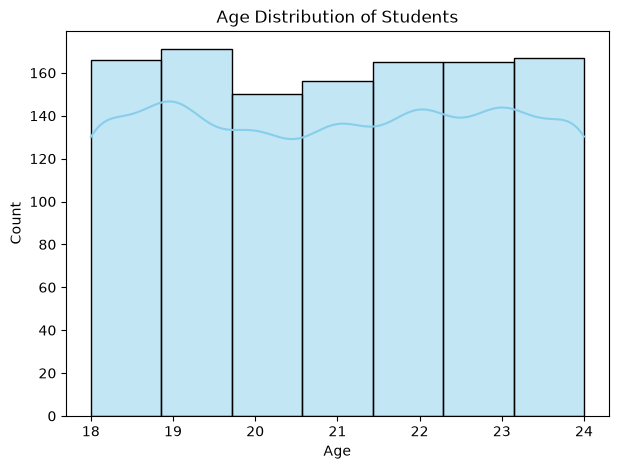

In [45]:
# Univariate Analysis - Age Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Age"], bins=7, kde=True, color="skyblue")
plt.title("Age Distribution of Students")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

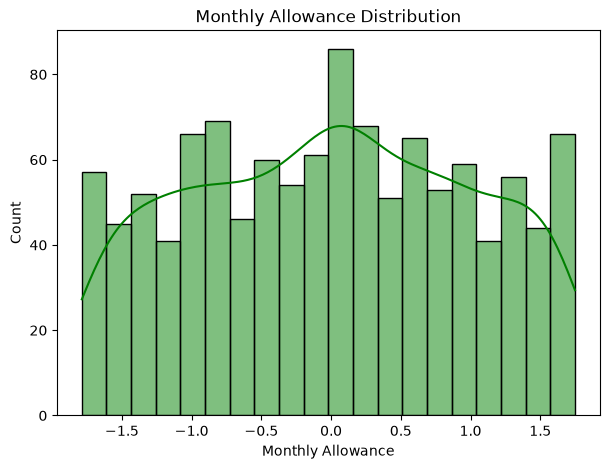

In [46]:
# Univariate Analysis - Monthly Allowance Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Monthly_Allowance"], bins=20, kde=True, color="green")
plt.title("Monthly Allowance Distribution")
plt.xlabel("Monthly Allowance")
plt.ylabel("Count")
plt.show()

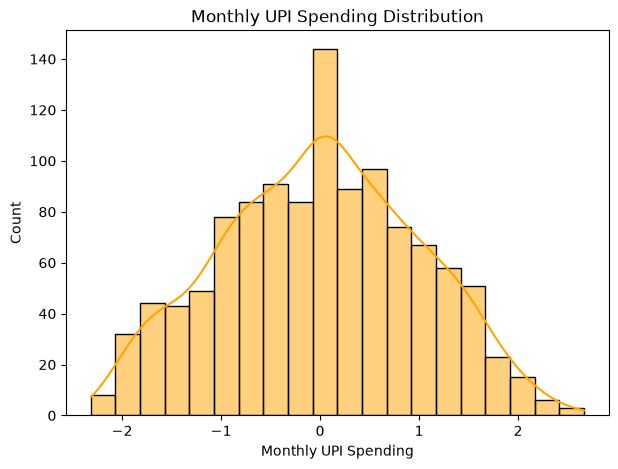

In [47]:
# Univariate Analysis - Monthly UPI Spending Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Monthly_UPI_Spending"], bins=20, kde=True, color="orange")
plt.title("Monthly UPI Spending Distribution")
plt.xlabel("Monthly UPI Spending")
plt.ylabel("Count")
plt.show()

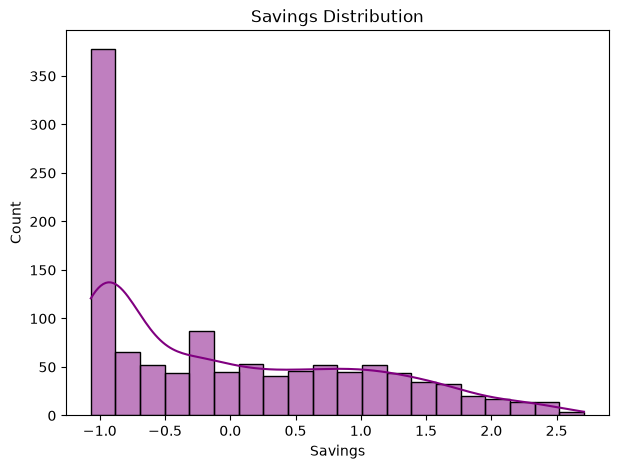

In [48]:
# Univariate Analysis - Savings Distribution

plt.figure(figsize=(7,5))
sns.histplot(df["Savings"], bins=20, kde=True, color="purple")
plt.title("Savings Distribution")
plt.xlabel("Savings")
plt.ylabel("Count")
plt.show()

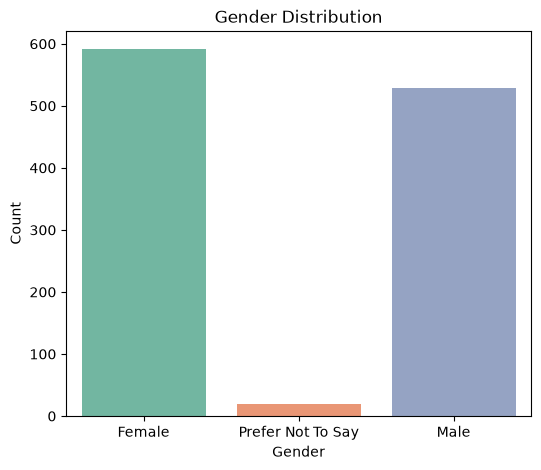

In [49]:
# Univariate Analysis - Gender Count Plot

df["Gender"] = (
    df["Gender"]
    .astype(str)
    .str.strip()
    .str.title()
)

df["Gender"] = df["Gender"].replace("Nan", np.nan)
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", legend=False)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

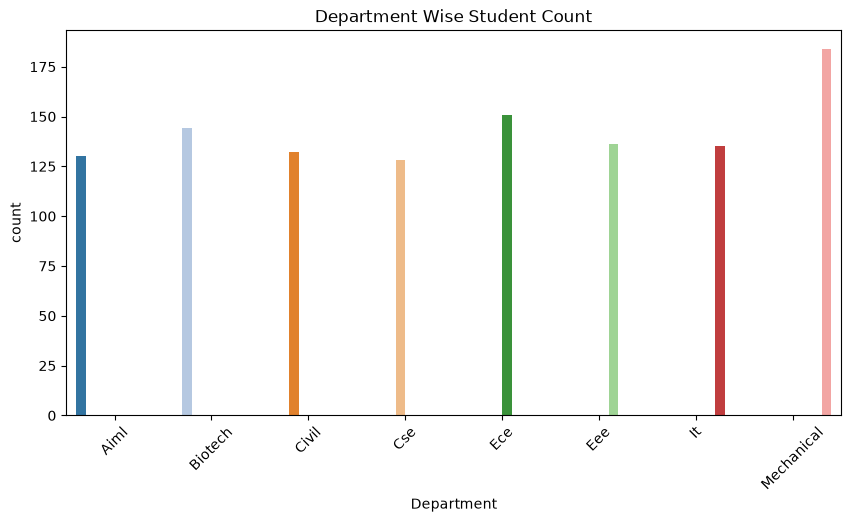

In [50]:
# Univariate Analysis - Department Count Plot

plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Department", hue="Department", legend=False, palette="tab20")
plt.xticks(rotation=45)
plt.title("Department Wise Student Count")
plt.show()

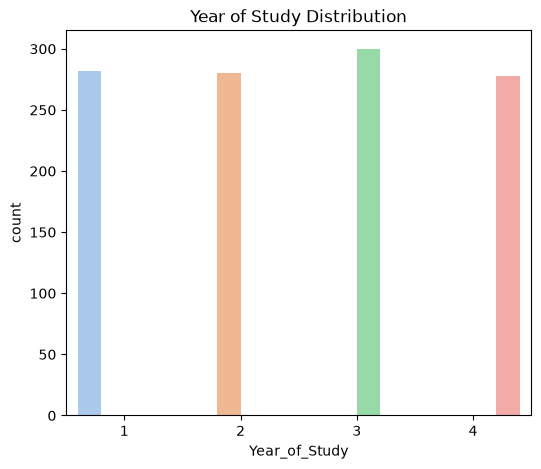

In [51]:
# Univariate Analysis - Year of Study Count Plot

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Year_of_Study", hue="Year_of_Study", legend=False, palette="pastel")
plt.title("Year of Study Distribution")
plt.show()

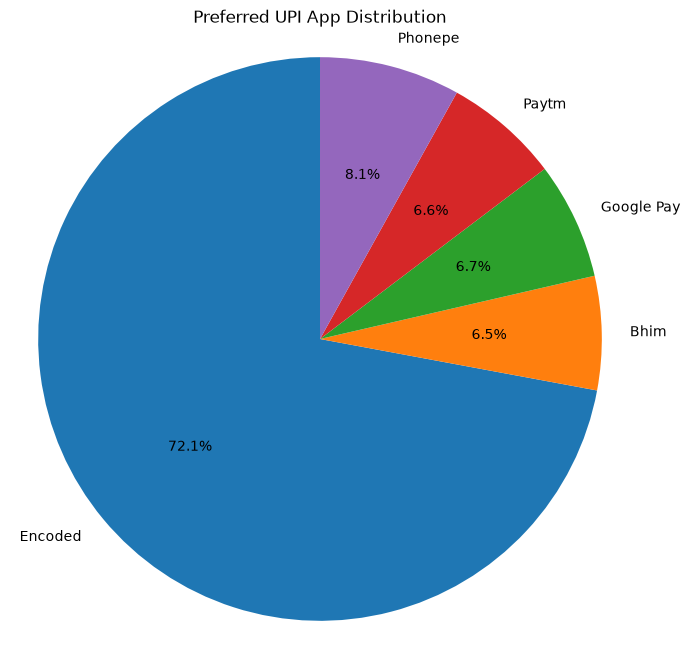

In [52]:
# Univariate Analysis - Preferred UPI App Pie Chart

app_columns = [col for col in df.columns if col.startswith("Preferred_UPI_App_")]

app_counts = df[app_columns].sum()

app_names = [col.replace("Preferred_UPI_App_", "") for col in app_columns]

plt.figure(figsize=(8,8))
plt.pie(app_counts, labels=app_names, autopct="%1.1f%%", startangle=90)
plt.title("Preferred UPI App Distribution")
plt.axis("equal")
plt.show()

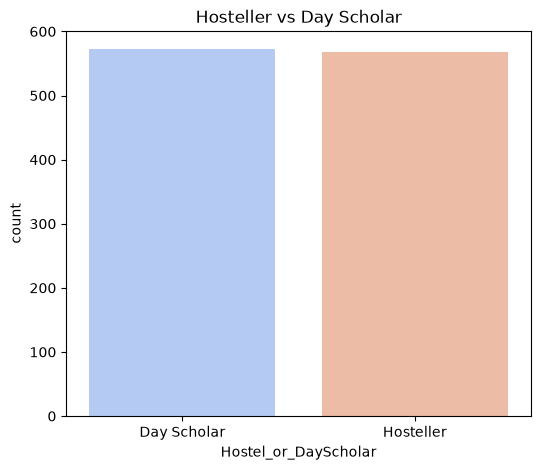

In [53]:
# Univariate Analysis - Hostel vs Day Scholar

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Hostel_or_DayScholar", hue="Hostel_or_DayScholar", legend=False, palette="coolwarm")
plt.title("Hosteller vs Day Scholar")
plt.show()

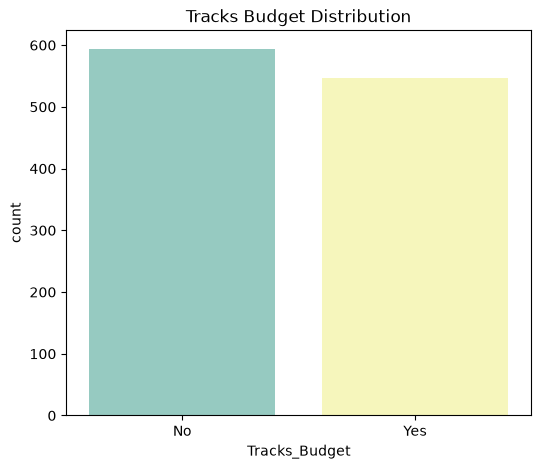

In [54]:
# Univariate Analysis - Tracks Budget Count Plot

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Tracks_Budget", hue="Tracks_Budget", legend=False, palette="Set3")
plt.title("Tracks Budget Distribution")
plt.show()

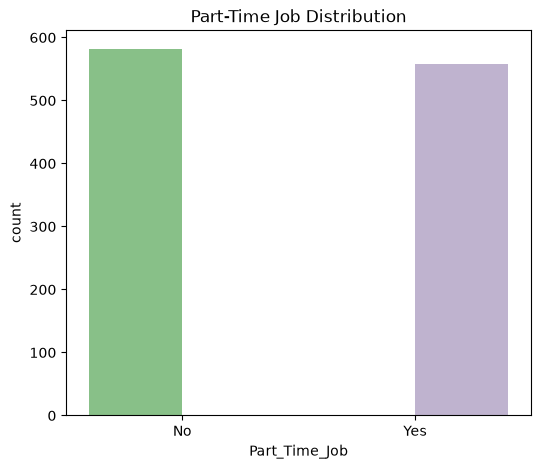

In [55]:
# Univariate Analysis - Part-Time Job Count Plot

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Part_Time_Job", hue="Part_Time_Job", legend=False, palette="Accent")
plt.title("Part-Time Job Distribution")
plt.show()

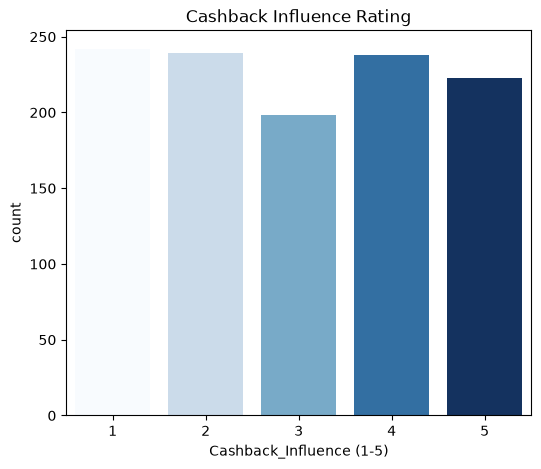

In [56]:
# Univariate Analysis - Cashback Influence Distribution

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Cashback_Influence (1-5)", hue="Cashback_Influence (1-5)", legend=False, palette="Blues")
plt.title("Cashback Influence Rating")
plt.show()

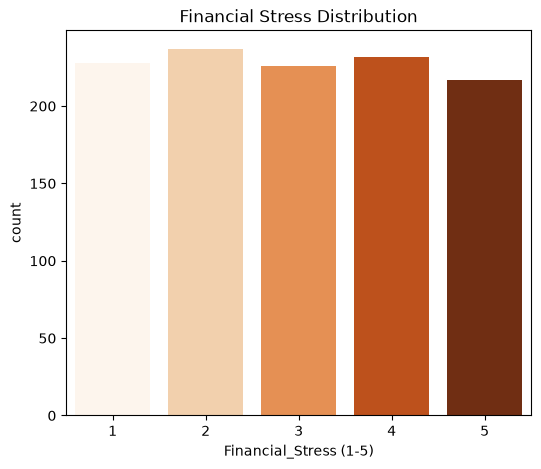

In [57]:
# Univariate Analysis - Financial Stress Distribution

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Financial_Stress (1-5)", hue="Financial_Stress (1-5)", legend=False, palette="Oranges")
plt.title("Financial Stress Distribution")
plt.show()

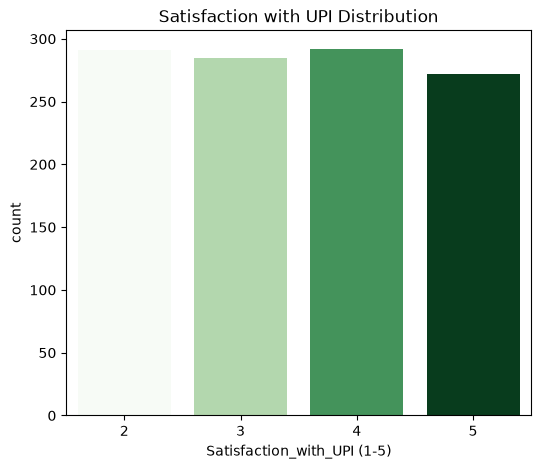

In [58]:
# Univariate Analysis - Satisfaction with UPI Distribution

plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Satisfaction_with_UPI (1-5)", hue="Satisfaction_with_UPI (1-5)", legend=False, palette="Greens")
plt.title("Satisfaction with UPI Distribution")
plt.show()

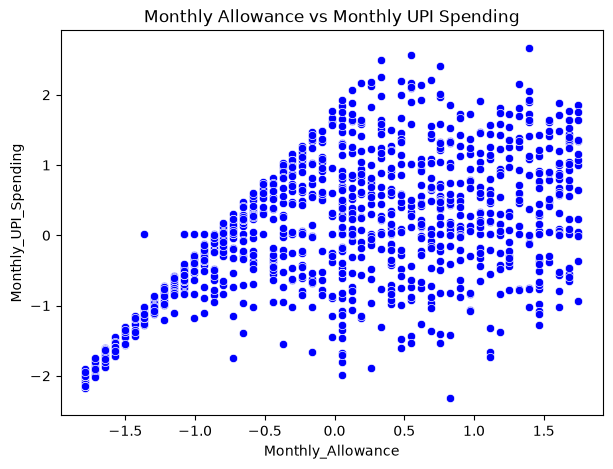

In [59]:
# Bivariate Analysis - Monthly Allowance vs Monthly UPI Spending

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Monthly_Allowance", y="Monthly_UPI_Spending", color="blue")
plt.title("Monthly Allowance vs Monthly UPI Spending")
plt.show()

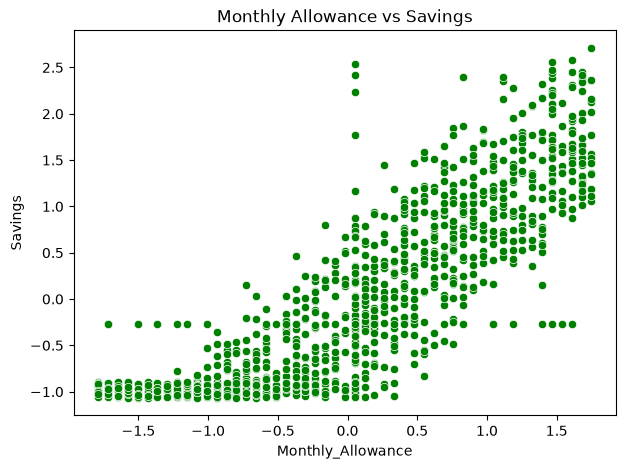

In [60]:
# Bivariate Analysis - Monthly Allowance vs Savings

plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Monthly_Allowance", y="Savings", color="green")
plt.title("Monthly Allowance vs Savings")
plt.show()

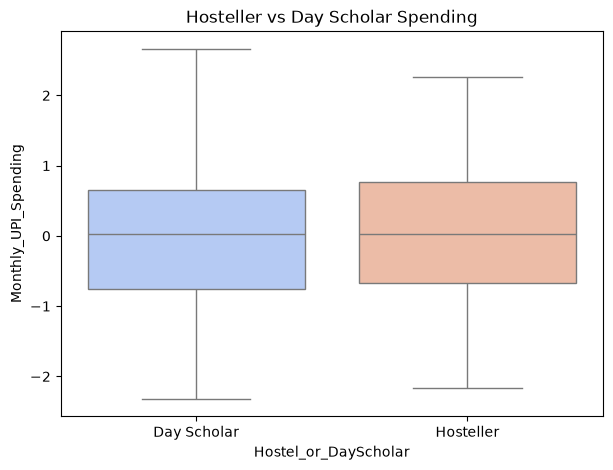

In [61]:
# Bivariate Analysis - Hostel vs Spending

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x="Hostel_or_DayScholar", y="Monthly_UPI_Spending", hue="Hostel_or_DayScholar", legend=False, palette="coolwarm")
plt.title("Hosteller vs Day Scholar Spending")
plt.show()

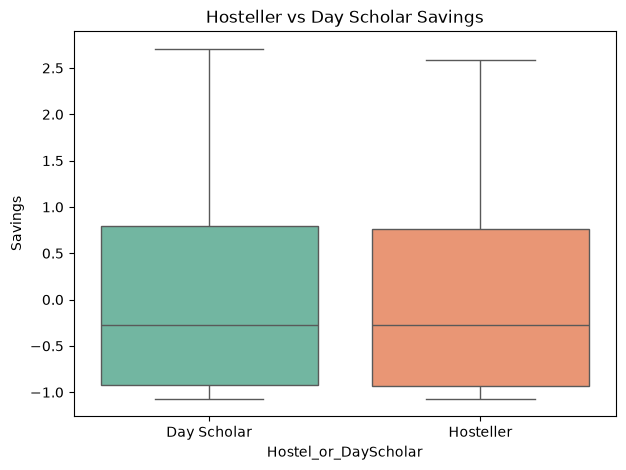

In [62]:
# Bivariate Analysis - Hostel vs Savings

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x="Hostel_or_DayScholar", y="Savings", hue="Hostel_or_DayScholar", legend=False, palette="Set2")
plt.title("Hosteller vs Day Scholar Savings")
plt.show()

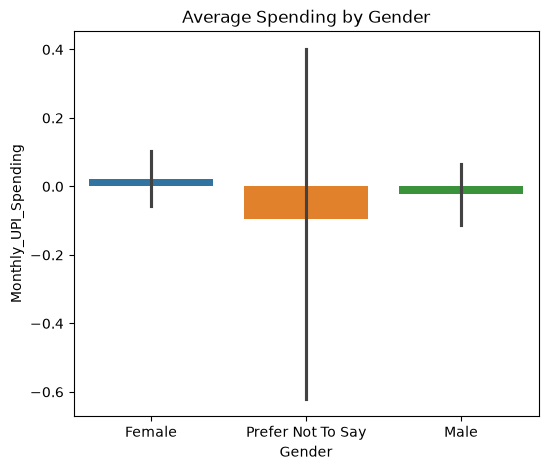

In [63]:
# Bivariate Analysis - Gender vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Gender", y="Monthly_UPI_Spending", hue="Gender", legend=False)
plt.title("Average Spending by Gender")
plt.show()

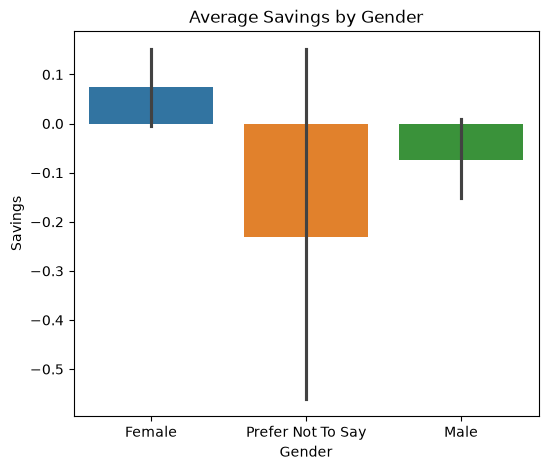

In [64]:
# Bivariate Analysis - Gender vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Gender", y="Savings", hue="Gender", legend=False)
plt.title("Average Savings by Gender")
plt.show()

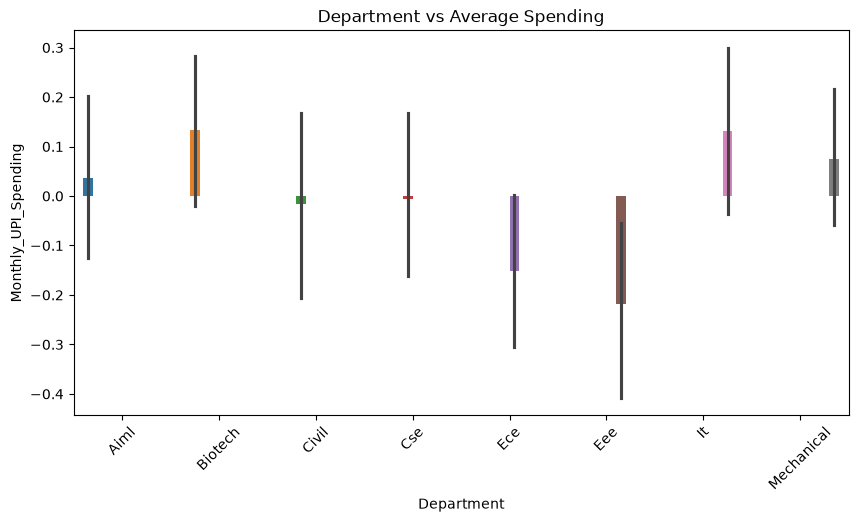

In [65]:
# Bivariate Analysis - Department vs Spending

plt.figure(figsize=(10,5))
sns.barplot(data=df, x="Department", y="Monthly_UPI_Spending", hue="Department", legend=False)
plt.xticks(rotation=45)
plt.title("Department vs Average Spending")
plt.show()

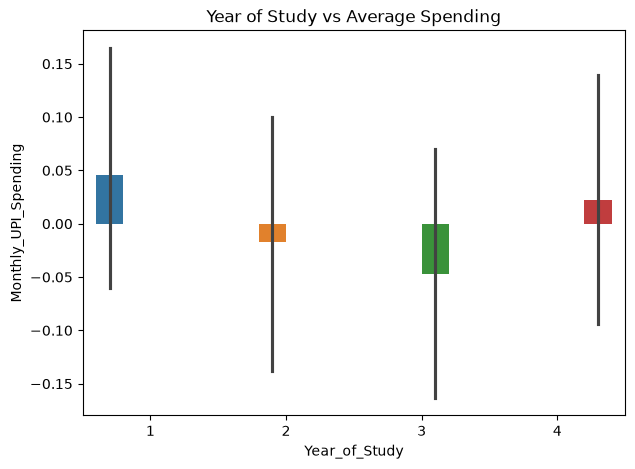

In [66]:
# Bivariate Analysis - Year of Study vs Spending

plt.figure(figsize=(7,5))
sns.barplot(data=df, x="Year_of_Study", y="Monthly_UPI_Spending", hue="Year_of_Study", legend=False)
plt.title("Year of Study vs Average Spending")
plt.show()

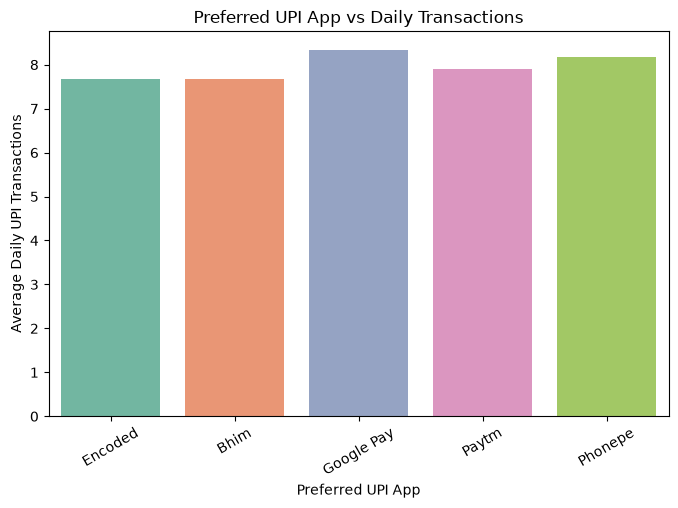

In [67]:
# Bivariate Analysis - Preferred UPI App vs Daily Transactions

plt.figure(figsize=(8,5))

if "Preferred_UPI_App" in df.columns:
    df["Preferred_UPI_App"] = (
        df["Preferred_UPI_App"]
        .astype(str)
        .str.strip()
        .str.title()
    )

    sns.barplot(
        data=df,
        x="Preferred_UPI_App",
        y="Daily_UPI_Transactions",
        estimator="mean",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

else:
    app_columns = [col for col in df.columns if col.startswith("Preferred_UPI_App_")]

    temp_df = pd.DataFrame({
        "Preferred_UPI_App": [col.replace("Preferred_UPI_App_", "") for col in app_columns],
        "Average_Transactions": [df.loc[df[col] == 1, "Daily_UPI_Transactions"].mean() for col in app_columns]
    })

    sns.barplot(
        data=temp_df,
        x="Preferred_UPI_App",
        y="Average_Transactions",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

plt.xticks(rotation=30)
plt.title("Preferred UPI App vs Daily Transactions")
plt.xlabel("Preferred UPI App")
plt.ylabel("Average Daily UPI Transactions")
plt.show()

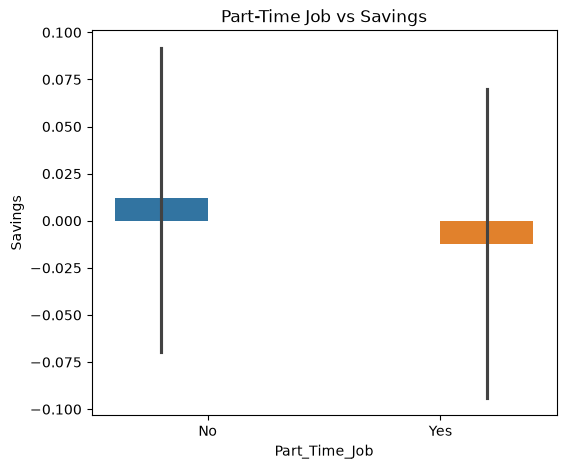

In [68]:
# Bivariate Analysis - Part-Time Job vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Part_Time_Job", y="Savings", hue="Part_Time_Job", legend=False)
plt.title("Part-Time Job vs Savings")
plt.show()

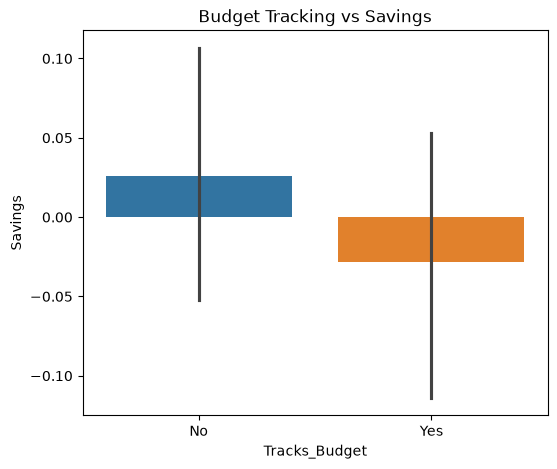

In [69]:
# Bivariate Analysis - Budget Tracking vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Tracks_Budget", y="Savings", hue="Tracks_Budget", legend=False)
plt.title("Budget Tracking vs Savings")
plt.show()

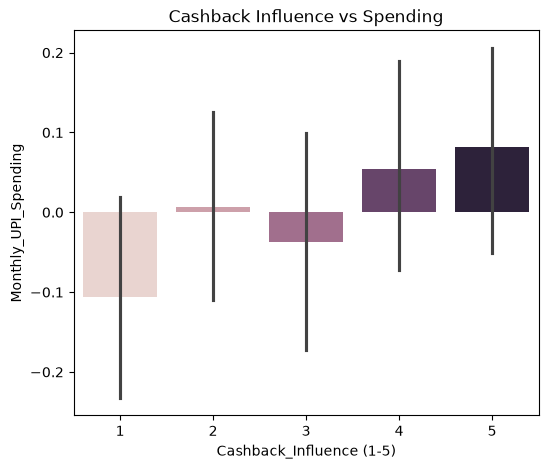

In [70]:
# Bivariate Analysis - Cashback Influence vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Cashback_Influence (1-5)", y="Monthly_UPI_Spending", hue="Cashback_Influence (1-5)", legend=False)
plt.title("Cashback Influence vs Spending")
plt.show()

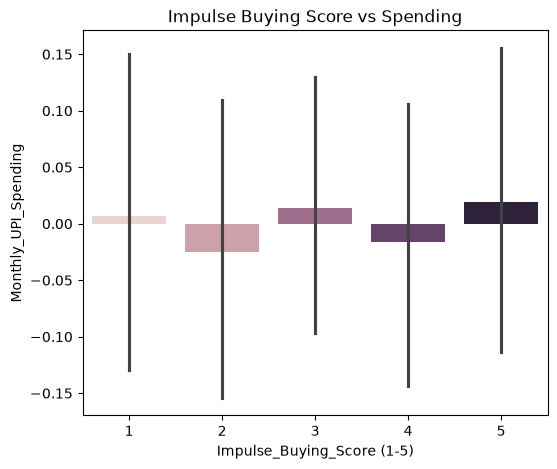

In [71]:
# Bivariate Analysis - Impulse Buying Score vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Impulse_Buying_Score (1-5)", y="Monthly_UPI_Spending", hue="Impulse_Buying_Score (1-5)", legend=False)
plt.title("Impulse Buying Score vs Spending")
plt.show()

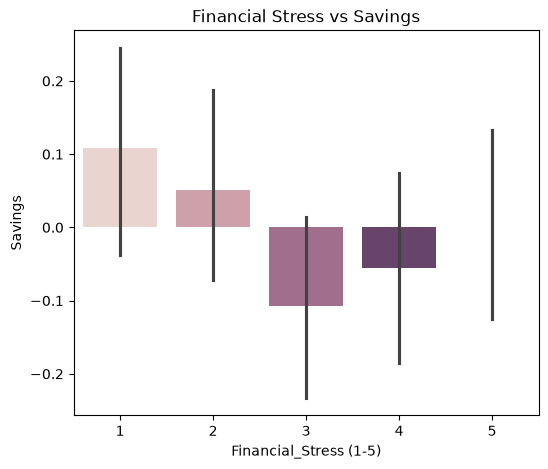

In [72]:
# Bivariate Analysis - Financial Stress vs Savings

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Financial_Stress (1-5)", y="Savings", hue="Financial_Stress (1-5)", legend=False)
plt.title("Financial Stress vs Savings")
plt.show()

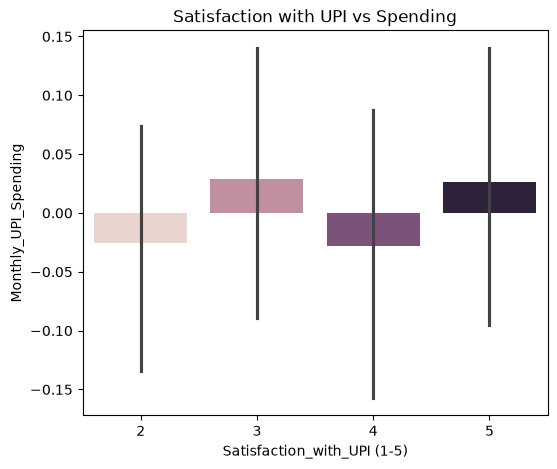

In [73]:
# Bivariate Analysis - Satisfaction with UPI vs Spending

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Satisfaction_with_UPI (1-5)", y="Monthly_UPI_Spending", hue="Satisfaction_with_UPI (1-5)", legend=False)
plt.title("Satisfaction with UPI vs Spending")
plt.show()

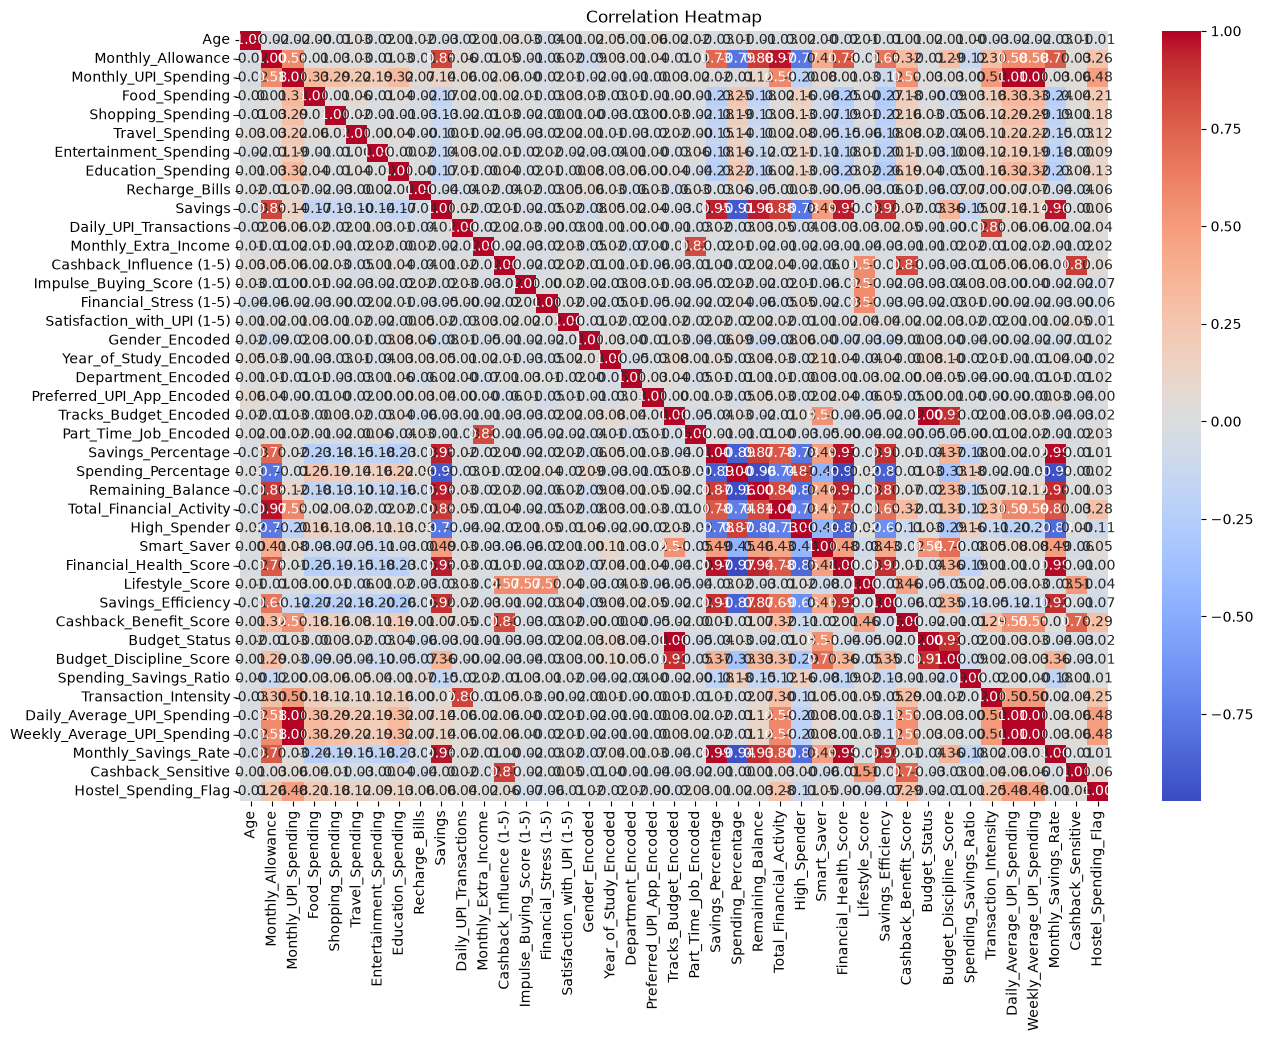

In [74]:
# Multivariate Analysis - Correlation Heatmap

numeric_df = df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(14,10))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

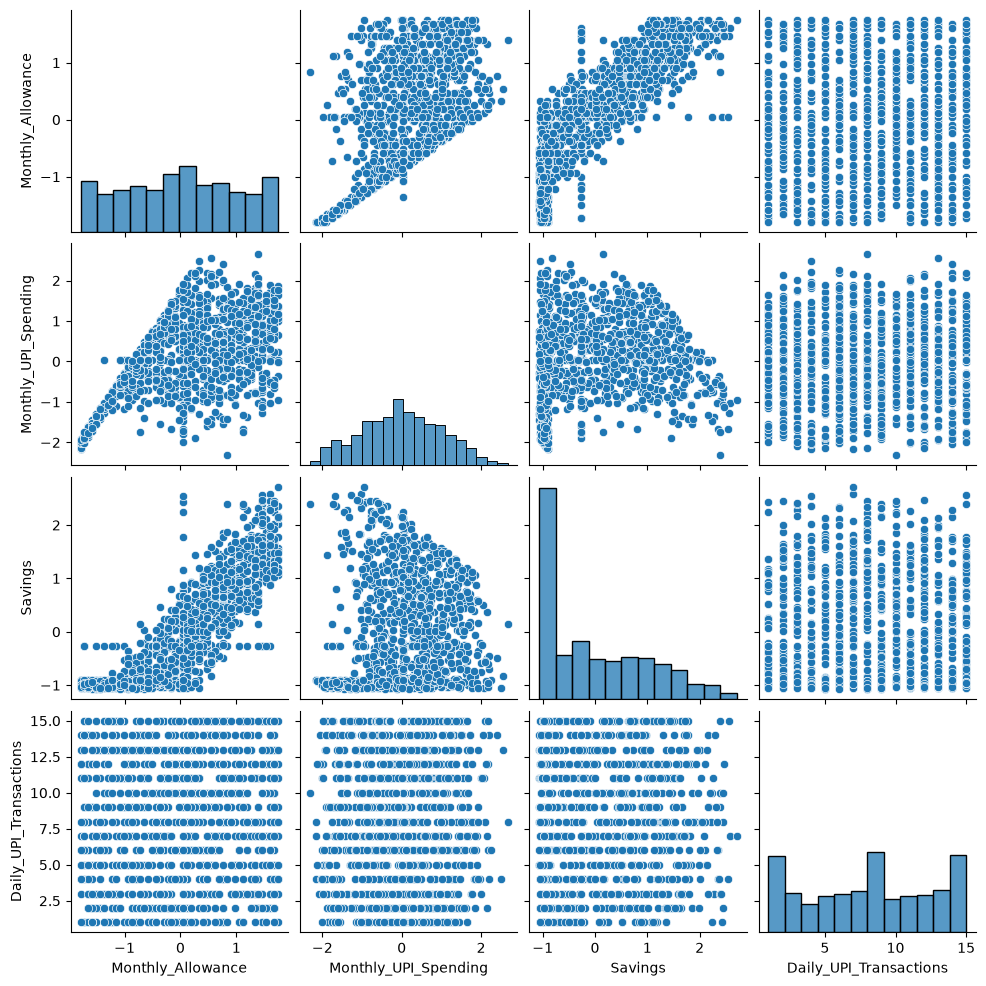

In [75]:
# Multivariate Analysis - Pair Plot

pair_columns = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Daily_UPI_Transactions"
]

sns.pairplot(df[pair_columns].dropna())
plt.show()

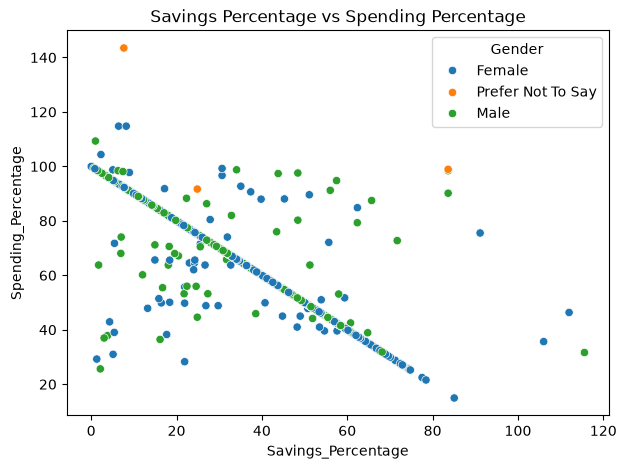

In [76]:
# Multivariate Analysis - Savings Percentage vs Spending Percentage

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Savings_Percentage",
    y="Spending_Percentage",
    hue="Gender"
)
plt.title("Savings Percentage vs Spending Percentage")
plt.show()

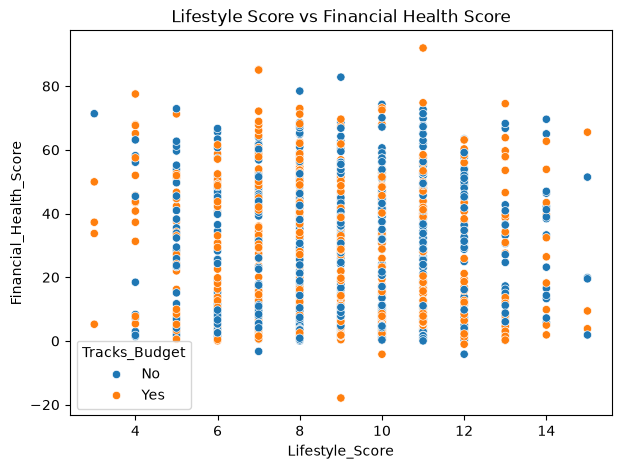

In [77]:
# Multivariate Analysis - Lifestyle Score vs Financial Health Score

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Lifestyle_Score",
    y="Financial_Health_Score",
    hue="Tracks_Budget"
)
plt.title("Lifestyle Score vs Financial Health Score")
plt.show()

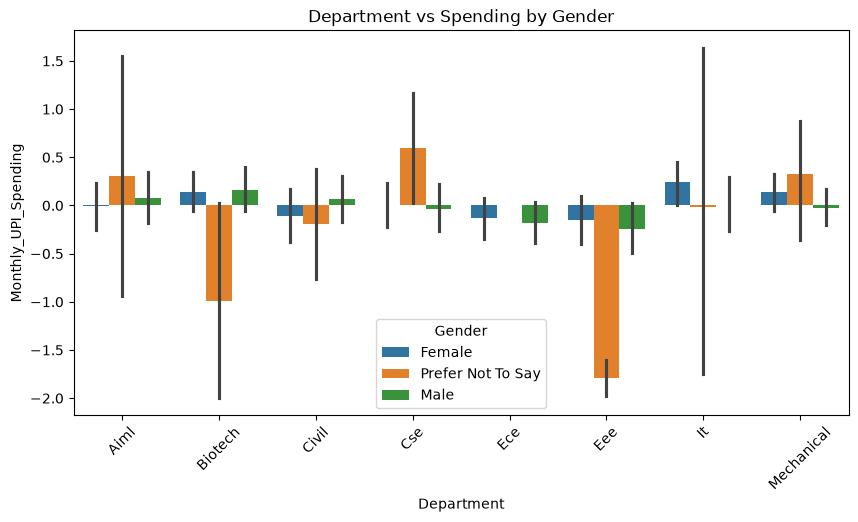

In [78]:
# Multivariate Analysis - Department vs Spending by Gender

plt.figure(figsize=(10,5))
sns.barplot(
    data=df,
    x="Department",
    y="Monthly_UPI_Spending",
    hue="Gender"
)
plt.xticks(rotation=45)
plt.title("Department vs Spending by Gender")
plt.show()

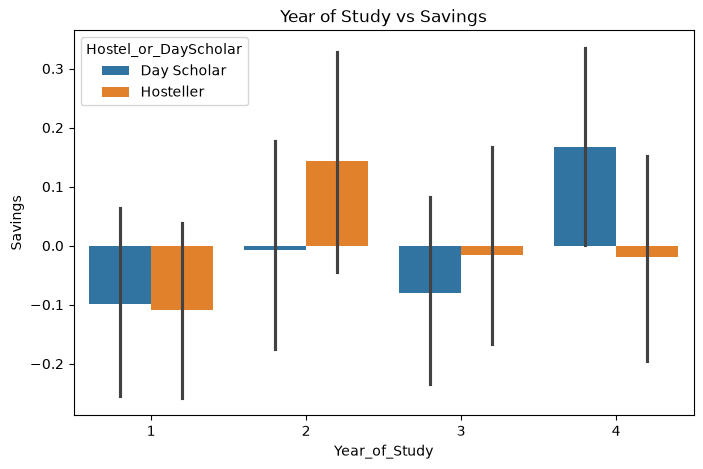

In [79]:
# Multivariate Analysis - Year of Study vs Savings

plt.figure(figsize=(8,5))
sns.barplot(
    data=df,
    x="Year_of_Study",
    y="Savings",
    hue="Hostel_or_DayScholar"
)
plt.title("Year of Study vs Savings")
plt.show()

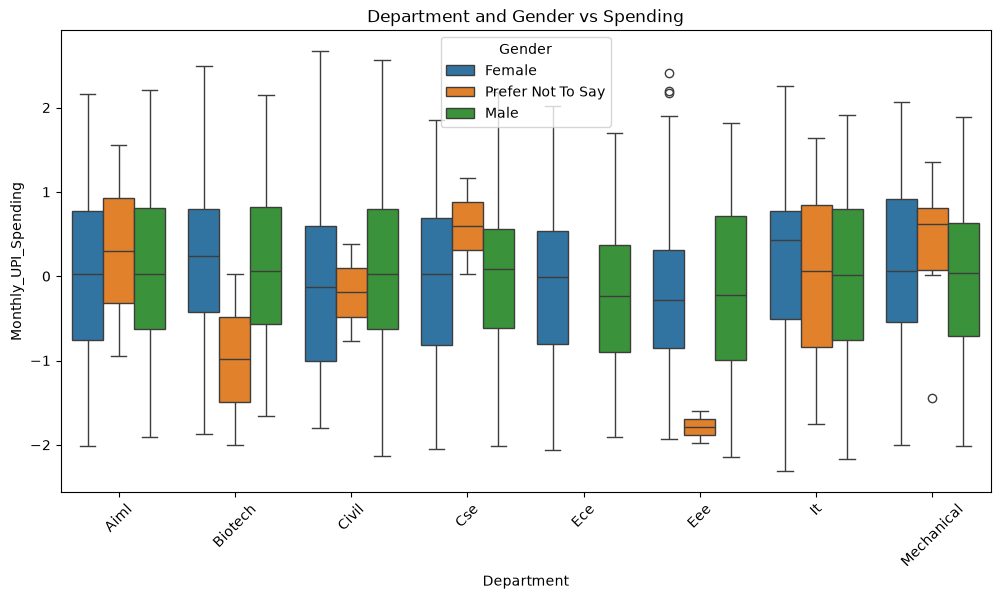

In [80]:
# Multivariate Analysis - Spending Distribution by Department and Gender

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df,
    x="Department",
    y="Monthly_UPI_Spending",
    hue="Gender"
)
plt.xticks(rotation=45)
plt.title("Department and Gender vs Spending")
plt.show()

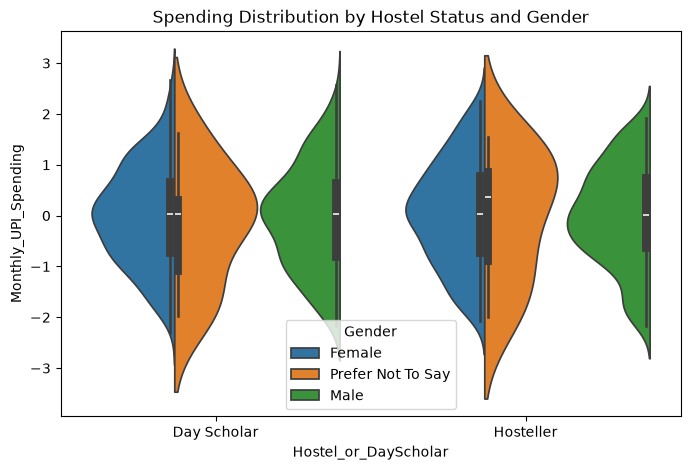

In [81]:
# Multivariate Analysis - Spending Distribution by Hostel Status

plt.figure(figsize=(8,5))
sns.violinplot(
    data=df,
    x="Hostel_or_DayScholar",
    y="Monthly_UPI_Spending",
    hue="Gender",
    split=True
)
plt.title("Spending Distribution by Hostel Status and Gender")
plt.show()

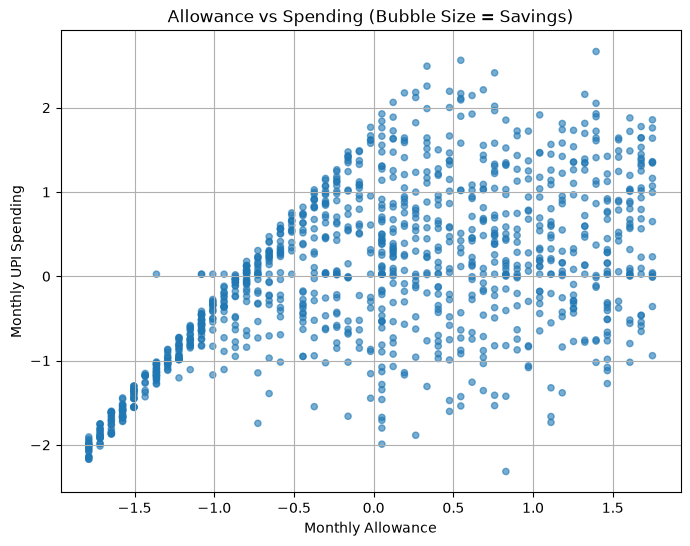

In [82]:
# Multivariate Analysis - Bubble Plot

bubble_df = df[["Monthly_Allowance", "Monthly_UPI_Spending", "Savings"]].copy()

bubble_df["Monthly_Allowance"] = bubble_df["Monthly_Allowance"].fillna(
    bubble_df["Monthly_Allowance"].median()
)

bubble_df["Monthly_UPI_Spending"] = bubble_df["Monthly_UPI_Spending"].fillna(
    bubble_df["Monthly_UPI_Spending"].median()
)

bubble_df["Savings"] = bubble_df["Savings"].fillna(
    bubble_df["Savings"].median()
)

bubble_size = (bubble_df["Savings"].abs() / 10) + 20

plt.figure(figsize=(8,6))

plt.scatter(
    bubble_df["Monthly_Allowance"],
    bubble_df["Monthly_UPI_Spending"],
    s=bubble_size,
    alpha=0.6
)

plt.xlabel("Monthly Allowance")
plt.ylabel("Monthly UPI Spending")
plt.title("Allowance vs Spending (Bubble Size = Savings)")
plt.grid(True)

plt.show()

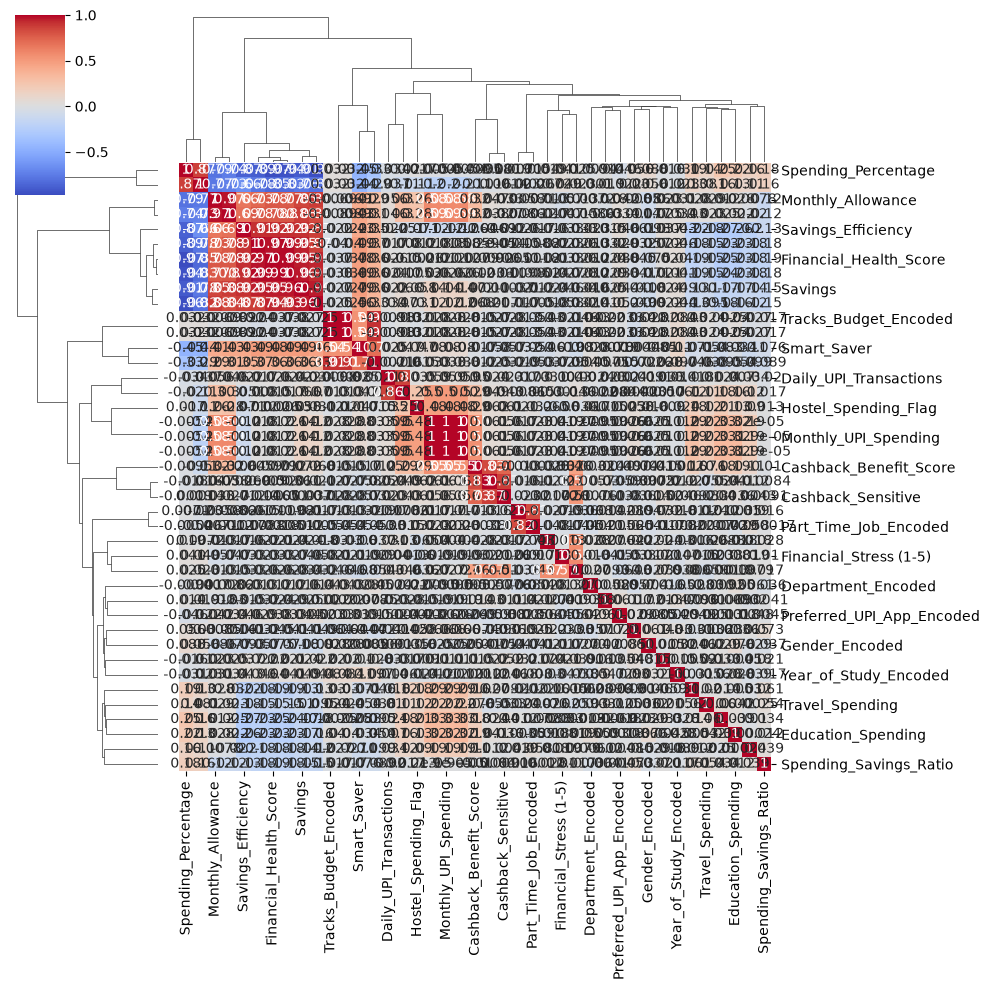

In [83]:
# Multivariate Analysis - Clustered Heatmap

numeric_df = df.select_dtypes(include=["int64","float64"])

sns.clustermap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True,
    figsize=(10,10)
)
plt.show()

Department with Highest Average UPI Spending:
Department
Biotech       0.134108
It            0.132082
Mechanical    0.073805
Aiml          0.036553
Cse          -0.005652
Name: Monthly_UPI_Spending, dtype: float64


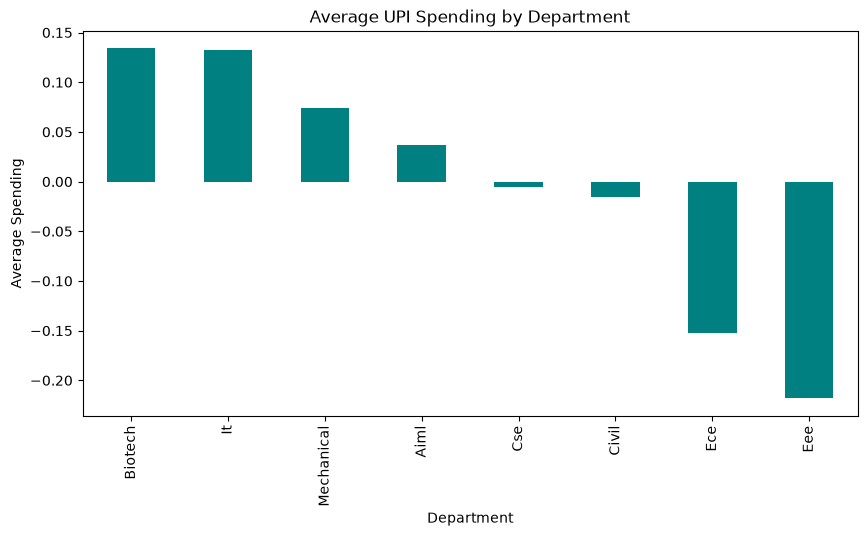

In [84]:
# Insight 1 - Highest Spending Department

department_spending = df.groupby("Department")["Monthly_UPI_Spending"].mean().sort_values(ascending=False)

print("Department with Highest Average UPI Spending:")
print(department_spending.head())

plt.figure(figsize=(10,5))
department_spending.plot(kind="bar", color="teal")
plt.title("Average UPI Spending by Department")
plt.xlabel("Department")
plt.ylabel("Average Spending")
plt.show()

Most Preferred UPI App:
  Preferred_UPI_App  Count
0           Encoded   2385
1           Phonepe    267
2        Google Pay    222
3             Paytm    219
4              Bhim    216


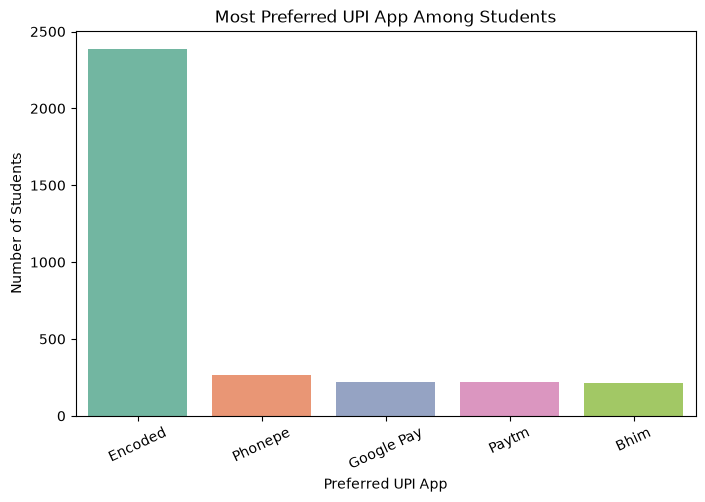

In [85]:
# Insight 2 - Most Preferred UPI App

plt.figure(figsize=(8,5))

if "Preferred_UPI_App" in df.columns:

    df["Preferred_UPI_App"] = (
        df["Preferred_UPI_App"]
        .astype(str)
        .str.strip()
        .str.title()
    )

    df["Preferred_UPI_App"] = df["Preferred_UPI_App"].replace("Nan", np.nan)
    df["Preferred_UPI_App"] = df["Preferred_UPI_App"].fillna(df["Preferred_UPI_App"].mode()[0])

    upi_count = df["Preferred_UPI_App"].value_counts()

    print("Most Preferred UPI App:")
    print(upi_count)

    sns.countplot(
        data=df,
        x="Preferred_UPI_App",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

else:

    app_columns = [col for col in df.columns if col.startswith("Preferred_UPI_App_")]

    app_count = df[app_columns].sum().sort_values(ascending=False)

    app_df = pd.DataFrame({
        "Preferred_UPI_App": app_count.index.str.replace("Preferred_UPI_App_", "", regex=False),
        "Count": app_count.values
    })

    print("Most Preferred UPI App:")
    print(app_df)

    sns.barplot(
        data=app_df,
        x="Preferred_UPI_App",
        y="Count",
        hue="Preferred_UPI_App",
        legend=False,
        palette="Set2"
    )

plt.title("Most Preferred UPI App Among Students")
plt.xticks(rotation=25)
plt.xlabel("Preferred UPI App")
plt.ylabel("Number of Students")
plt.show()

Gender
Female               0.022514
Male                -0.021561
Prefer Not To Say   -0.095020
Name: Monthly_UPI_Spending, dtype: float64


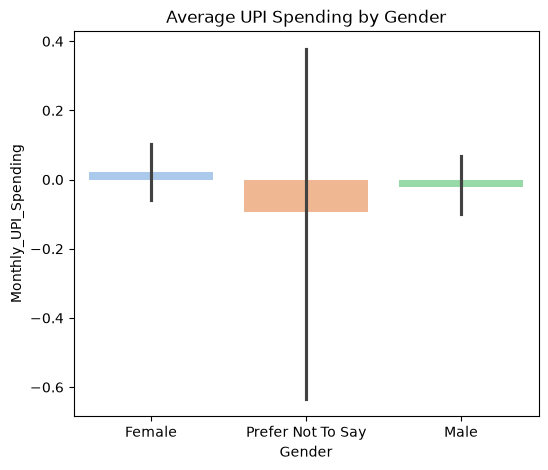

In [86]:
# Insight 3 - Average Spending by Gender

gender_spending = df.groupby("Gender")["Monthly_UPI_Spending"].mean()

print(gender_spending)

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Gender", y="Monthly_UPI_Spending", hue="Gender", legend=False, palette="pastel")
plt.title("Average UPI Spending by Gender")
plt.show()

Hostel_or_DayScholar
Day Scholar   -0.012874
Hosteller      0.012965
Name: Monthly_UPI_Spending, dtype: float64


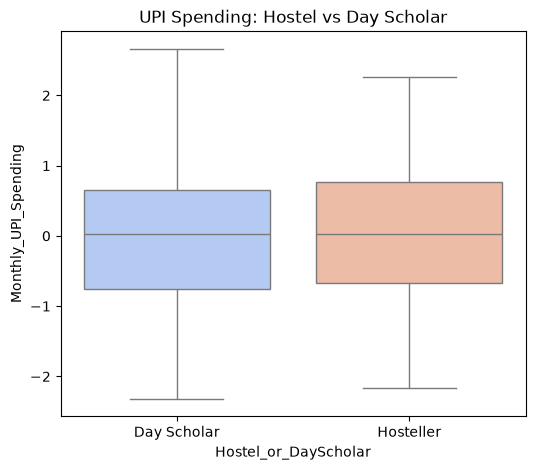

In [87]:
# Insight 4 - Hostel vs Day Scholar Spending

hostel_spending = df.groupby("Hostel_or_DayScholar")["Monthly_UPI_Spending"].mean()

print(hostel_spending)

plt.figure(figsize=(6,5))
sns.boxplot(data=df, x="Hostel_or_DayScholar", y="Monthly_UPI_Spending", hue="Hostel_or_DayScholar", legend=False, palette="coolwarm")
plt.title("UPI Spending: Hostel vs Day Scholar")
plt.show()

Tracks_Budget
No     0.026214
Yes   -0.028518
Name: Savings, dtype: float64


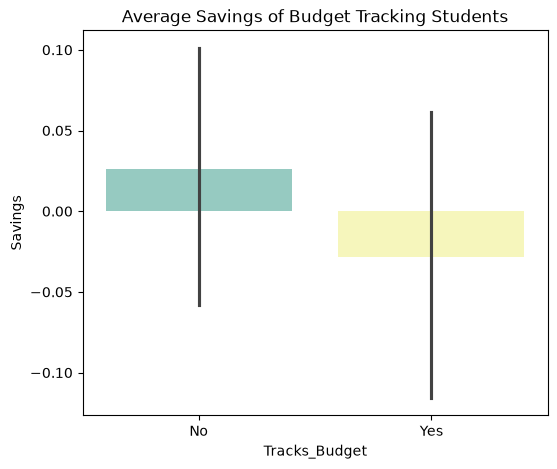

In [88]:
# Insight 5 - Budget Tracking and Savings

budget_savings = df.groupby("Tracks_Budget")["Savings"].mean()

print(budget_savings)

plt.figure(figsize=(6,5))
sns.barplot(data=df, x="Tracks_Budget", y="Savings", hue="Tracks_Budget", legend=False, palette="Set3")
plt.title("Average Savings of Budget Tracking Students")
plt.show()

Cashback_Influence (1-5)
1   -0.105619
2    0.006971
3   -0.037295
4    0.054411
5    0.082189
Name: Monthly_UPI_Spending, dtype: float64


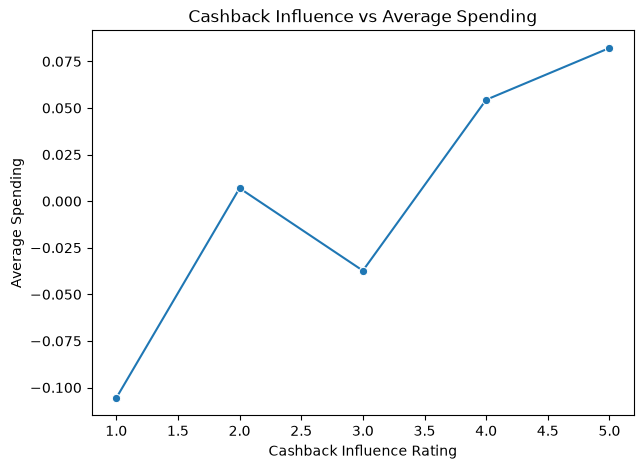

In [89]:
# Insight 6 - Cashback Influence on Spending

cashback_spending = df.groupby("Cashback_Influence (1-5)")["Monthly_UPI_Spending"].mean()

print(cashback_spending)

plt.figure(figsize=(7,5))
sns.lineplot(x=cashback_spending.index, y=cashback_spending.values, marker="o")
plt.title("Cashback Influence vs Average Spending")
plt.xlabel("Cashback Influence Rating")
plt.ylabel("Average Spending")
plt.show()

Impulse_Buying_Score (1-5)
1    0.006591
2   -0.025397
3    0.014286
4   -0.016299
5    0.019063
Name: Monthly_UPI_Spending, dtype: float64


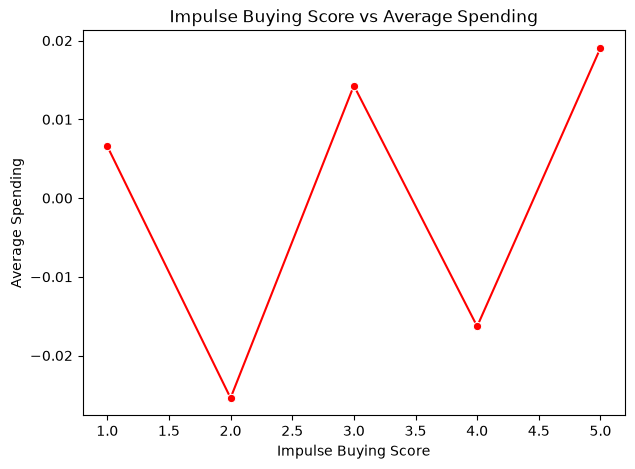

In [90]:
# Insight 7 - Impulse Buying and Spending

impulse_spending = df.groupby("Impulse_Buying_Score (1-5)")["Monthly_UPI_Spending"].mean()

print(impulse_spending)

plt.figure(figsize=(7,5))
sns.lineplot(x=impulse_spending.index, y=impulse_spending.values, marker="o", color="red")
plt.title("Impulse Buying Score vs Average Spending")
plt.xlabel("Impulse Buying Score")
plt.ylabel("Average Spending")
plt.show()

Financial_Stress (1-5)
1    0.108258
2    0.051188
3   -0.106938
4   -0.055172
5    0.000709
Name: Savings, dtype: float64


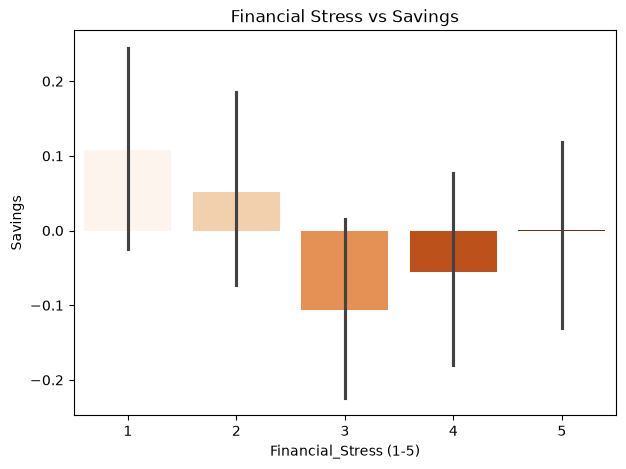

In [91]:
# Insight 8 - Financial Stress and Savings

stress_savings = df.groupby("Financial_Stress (1-5)")["Savings"].mean()

print(stress_savings)

plt.figure(figsize=(7,5))
sns.barplot(data=df, x="Financial_Stress (1-5)", y="Savings", hue="Financial_Stress (1-5)", legend=False, palette="Oranges")
plt.title("Financial Stress vs Savings")
plt.show()

Year_of_Study
1    0.045436
2   -0.017431
3   -0.046705
4    0.021868
Name: Monthly_UPI_Spending, dtype: float64


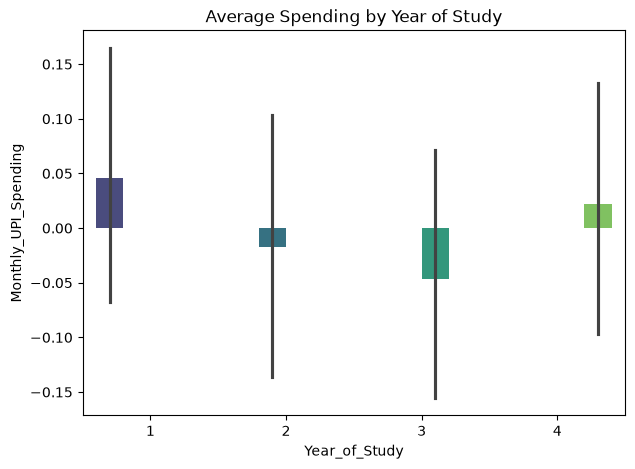

In [92]:
# Insight 9 - Year of Study Spending Trend

year_spending = df.groupby("Year_of_Study")["Monthly_UPI_Spending"].mean()

print(year_spending)

plt.figure(figsize=(7,5))
sns.barplot(data=df, x="Year_of_Study", y="Monthly_UPI_Spending", hue="Year_of_Study", legend=False, palette="viridis")
plt.title("Average Spending by Year of Study")
plt.show()

Correlation between Monthly Allowance and UPI Spending: 0.58


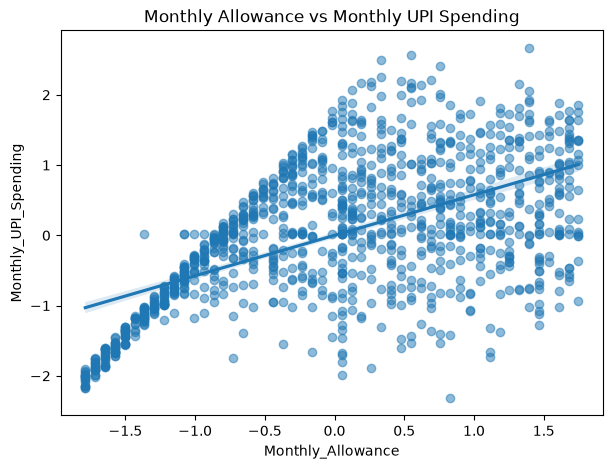

In [93]:
# Insight 10 - Correlation Between Allowance and Spending

correlation = df["Monthly_Allowance"].corr(df["Monthly_UPI_Spending"])

print("Correlation between Monthly Allowance and UPI Spending:", round(correlation,2))

plt.figure(figsize=(7,5))
sns.regplot(data=df, x="Monthly_Allowance", y="Monthly_UPI_Spending", scatter_kws={"alpha":0.5})
plt.title("Monthly Allowance vs Monthly UPI Spending")
plt.show()

In [94]:
# Recommendation 1 - Students with Low Savings

low_savers = df[df["Savings_Percentage"] < 20]

print("Number of Low Saving Students:", len(low_savers))

low_savers[["Student_ID","Savings_Percentage"]].head()

Number of Low Saving Students: 503


,Student_ID,Savings_Percentage
0,S0001,3.99
1,S0002,3.64
2,S0003,0.04
6,S0007,10.16
9,S0010,15.09


In [95]:
# Recommendation 2 - High Spenders

high_spenders = df[df["Spending_Percentage"] > 80]

print("Number of High Spenders:", len(high_spenders))

high_spenders[["Student_ID","Spending_Percentage"]].head()

Number of High Spenders: 501


,Student_ID,Spending_Percentage
0,S0001,96.01
1,S0002,96.36
2,S0003,99.96
6,S0007,89.84
9,S0010,84.91


In [96]:
# Recommendation 3 - Budget Conscious Students

budget_students = df[df["Tracks_Budget"] == "Yes"]

print("Average Savings:", budget_students["Savings"].mean())

budget_students[["Student_ID","Savings"]].head()

Average Savings: -0.02851848429877154


,Student_ID,Savings
1,S0002,-1.037241
4,S0005,0.222409
5,S0006,1.694973
6,S0007,-0.699070
9,S0010,-0.545924


In [97]:
# Recommendation 4 - Cashback Sensitive Students

cashback_students = df[df["Cashback_Influence (1-5)"] >= 4]

print("Average Spending:", cashback_students["Monthly_UPI_Spending"].mean())

cashback_students[["Student_ID","Cashback_Influence (1-5)"]].head()

Average Spending: 0.06784812741951456


,Student_ID,Cashback_Influence (1-5)
0,S0001,5
1,S0002,4
3,S0004,5
4,S0005,4
6,S0007,5


In [98]:
# Recommendation 5 - High Financial Stress Students

stress_students = df[df["Financial_Stress (1-5)"] >= 4]

print("Average Savings:", stress_students["Savings"].mean())

stress_students[["Student_ID","Financial_Stress (1-5)"]].head()

Average Savings: -0.02816504273736092


,Student_ID,Financial_Stress (1-5)
1,S0002,4
4,S0005,4
11,S0012,4
12,S0013,5
13,S0014,4


In [99]:
# Recommendation 6 - High Impulse Buying Students

impulse_students = df[df["Impulse_Buying_Score (1-5)"] >= 4]

print("Average Spending:", impulse_students["Monthly_UPI_Spending"].mean())

impulse_students[["Student_ID","Impulse_Buying_Score (1-5)"]].head()

Average Spending: 0.00028185184040154356


,Student_ID,Impulse_Buying_Score (1-5)
0,S0001,5
2,S0003,4
3,S0004,4
8,S0009,5
14,S0015,4


In [100]:
# Recommendation 7 - Excellent Financial Health Students

excellent_students = df[df["Financial_Health_Score"] >= 75]

print("Number of Excellent Financial Health Students:", len(excellent_students))

excellent_students[["Student_ID","Financial_Health_Score"]].head()

Number of Excellent Financial Health Students: 6


,Student_ID,Financial_Health_Score
49,S0050,85.18
174,S0175,82.82
184,S0185,77.53
265,S0266,91.97
357,S0358,85.06


In [101]:
# Recommendation 8 - Hostel Students Spending More Than Average

average_spending = df["Monthly_UPI_Spending"].mean()

hostel_high = df[
    (df["Hostel_or_DayScholar"] == "Hosteller") &
    (df["Monthly_UPI_Spending"] > average_spending)
]

print("Hostel Students Spending Above Average:", len(hostel_high))

hostel_high[["Student_ID","Monthly_UPI_Spending"]].head()

Hostel Students Spending Above Average: 300


,Student_ID,Monthly_UPI_Spending
4,S0005,1.219485
6,S0007,2.194226
7,S0008,0.880572
8,S0009,1.087327
9,S0010,1.640923


In [102]:
# Recommendation 9 - Students Saving More Than 30 Percent

good_savers = df[df["Savings_Percentage"] >= 30]

print("Number of Good Savers:", len(good_savers))

good_savers[["Student_ID","Savings_Percentage"]].head()

Number of Good Savers: 525


,Student_ID,Savings_Percentage
3,S0004,74.28
4,S0005,32.40
5,S0006,65.11
8,S0009,40.80
10,S0011,61.88


In [103]:
# Recommendation 10 - Top 10 Smart Savers

top_savers = df.sort_values("Financial_Health_Score", ascending=False).head(10)

print(top_savers[[
    "Student_ID",
    "Savings_Percentage",
    "Financial_Health_Score"
]])

    Student_ID  Savings_Percentage  Financial_Health_Score
265      S0266              115.58                   91.97
49       S0050              106.02                   85.18
357      S0358               85.06                   85.06
174      S0175              111.98                   82.82
614      S0615               78.45                   78.45
184      S0185               77.53                   77.53
694      S0695               74.78                   74.78
39       S0040               74.50                   74.50
3        S0004               74.28                   74.28
263      S0264               73.17                   73.17


# PART 2 : EXPLORATORY DATA ANALYSIS (EDA)

Preprocessing is completed in Part 1. In this part we explore the cleaned data
using graphs and write down what we understand from each graph.

**Small note about the data used here**

In Phase 17 and Phase 18 we normalised and standardised `Monthly_Allowance`,
`Monthly_UPI_Spending` and `Savings`. After that these columns became z-scores
(values like -1.22, 0.47) instead of rupees. Graphs in rupees are much easier to
explain in the report, so in the next cell we bring back the original rupee values
from the raw CSV into three **new** columns:

* `Allowance_INR`
* `Spending_INR`
* `Savings_INR`

We also rebuild a single `UPI_App` column, because One Hot Encoding with
`drop_first=True` removed one app from the dummy columns.

None of the earlier code or columns is changed or deleted.

In [104]:
# ==========================================================
# PART 2 : EDA - SETUP FOR VISUALIZATION
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# ---------------------------------------------------------
# NOTE :
# In Phase 17 and Phase 18 we normalised and standardised
# Monthly_Allowance, Monthly_UPI_Spending and Savings.
# So those columns are now z-scores, not rupees.
# For graphs we want real rupee values, so we bring the
# original numbers back from the raw CSV using Student_ID.
# Old columns are NOT touched. We only add new columns.
# ---------------------------------------------------------

try:
    raw = pd.read_csv("UPI_Student_Spending_Dataset_Realistic_EDA.csv")
    raw = raw.drop_duplicates(subset="Student_ID").set_index("Student_ID")

    df["Allowance_INR"] = df["Student_ID"].map(raw["Monthly_Allowance"])
    df["Spending_INR"]  = df["Student_ID"].map(raw["Monthly_UPI_Spending"])
    df["Savings_INR"]   = df["Student_ID"].map(raw["Savings"])

    df["UPI_App"] = df["Student_ID"].map(raw["Preferred_UPI_App"])

    print("Original rupee values restored from raw CSV.")

except FileNotFoundError:
    df["Allowance_INR"] = df["Monthly_Allowance"]
    df["Spending_INR"]  = df["Monthly_UPI_Spending"]
    df["Savings_INR"]   = df["Savings"]

    app_cols = [c for c in df.columns
                if c.startswith("Preferred_UPI_App_") and c != "Preferred_UPI_App_Encoded"]
    df["UPI_App"] = "Other App"
    for c in app_cols:
        df.loc[df[c] == True, "UPI_App"] = c.replace("Preferred_UPI_App_", "")

    print("Raw CSV not found. Using scaled columns instead.")

# Fill any gaps created by the mapping
for c in ["Allowance_INR", "Spending_INR", "Savings_INR"]:
    df[c] = df[c].fillna(df[c].median())

# Clean the app names
df["UPI_App"] = df["UPI_App"].astype(str).str.strip().str.title()
df["UPI_App"] = df["UPI_App"].replace("Nan", np.nan)
df["UPI_App"] = df["UPI_App"].fillna(df["UPI_App"].mode()[0])

# Savings Percentage recalculated on rupee values (safe version)
df["Savings_Pct"] = ((df["Savings_INR"] / df["Allowance_INR"]) * 100).round(2)

print("\nColumns ready for EDA :")
print(df[["Allowance_INR", "Spending_INR", "Savings_INR", "Savings_Pct", "UPI_App"]].head())
print("\nRows used for EDA :", df.shape[0])


Raw CSV not found. Using scaled columns instead.

Columns ready for EDA :
   Allowance_INR  Spending_INR  Savings_INR  Savings_Pct    UPI_App
0      -1.221462     -0.808704    -1.006577        82.41      Paytm
1      -1.787276     -1.931463    -1.037241        58.03    Phonepe
2      -0.655649      0.470001    -1.067905       162.88  Other App
3       1.183245     -1.382272     2.276896       192.43      Paytm
4       0.758885      1.219485     0.222409        29.31      Paytm

Rows used for EDA : 1140


## 1. Histograms

Histograms tell us how the values of one column are spread out and where most
students are concentrated.

### 1.1 Histogram of Monthly UPI Spending

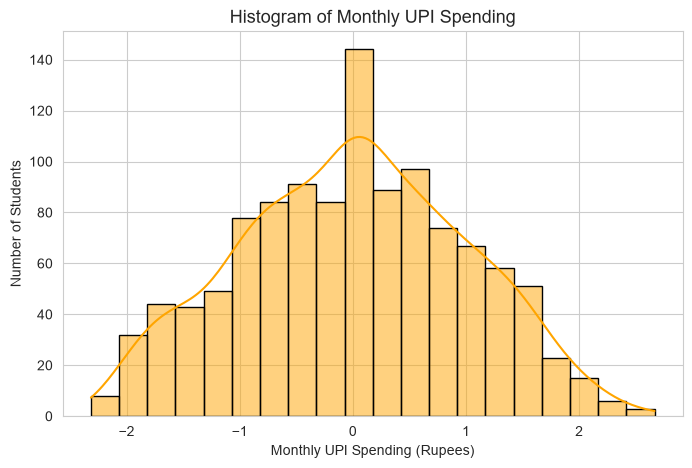

Minimum Spending : -2.32
Maximum Spending : 2.67
Average Spending : 0.0
Median Spending  : 0.02


In [105]:
# ----------------------------------------------------------
# HISTOGRAM 1 : MONTHLY UPI SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.histplot(df["Spending_INR"], bins=20, kde=True, color="orange", edgecolor="black")
plt.title("Histogram of Monthly UPI Spending", fontsize=13)
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.ylabel("Number of Students")
plt.show()

print("Minimum Spending :", round(df["Spending_INR"].min(), 2))
print("Maximum Spending :", round(df["Spending_INR"].max(), 2))
print("Average Spending :", round(df["Spending_INR"].mean(), 2))
print("Median Spending  :", round(df["Spending_INR"].median(), 2))


**Observations**

1. The graph shows how many students fall into each range of monthly UPI spending.
2. The bars are tallest in the middle ranges, so most students spend a moderate
   amount every month rather than a very small or very large amount.
3. The right side of the graph has fewer and shorter bars. This means only a small
   group of students spend very high amounts through UPI.
4. Since the mean and the median printed above are close to each other, the spending
   data is fairly balanced and not badly skewed.
5. Overall, UPI spending is a regular habit for students, not an occasional activity.

### 1.2 Histogram of Monthly Allowance

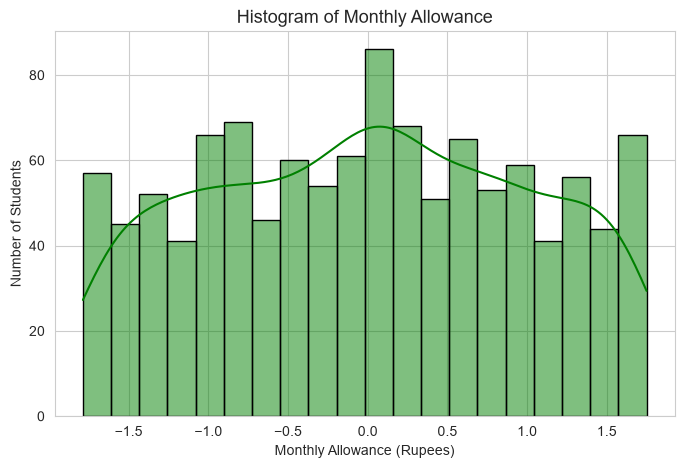

Minimum Allowance : -1.79
Maximum Allowance : 1.75
Average Allowance : 0.0
Median Allowance  : 0.05


In [106]:
# ----------------------------------------------------------
# HISTOGRAM 2 : MONTHLY ALLOWANCE
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.histplot(df["Allowance_INR"], bins=20, kde=True, color="green", edgecolor="black")
plt.title("Histogram of Monthly Allowance", fontsize=13)
plt.xlabel("Monthly Allowance (Rupees)")
plt.ylabel("Number of Students")
plt.show()

print("Minimum Allowance :", round(df["Allowance_INR"].min(), 2))
print("Maximum Allowance :", round(df["Allowance_INR"].max(), 2))
print("Average Allowance :", round(df["Allowance_INR"].mean(), 2))
print("Median Allowance  :", round(df["Allowance_INR"].median(), 2))


**Observations**

1. The graph shows the distribution of the monthly pocket money received by students.
2. Most students receive an allowance somewhere in the middle range, which is visible
   from the tall bars in the centre of the graph.
3. Very low and very high allowances are rare, so the extreme bars are short.
4. The allowance values are spread over a wide range, which shows that students come
   from different family backgrounds.
5. Because outliers were already removed in Phase 10, there are no extreme values
   pulling the graph to one side.

### 1.3 Histogram of Savings Percentage

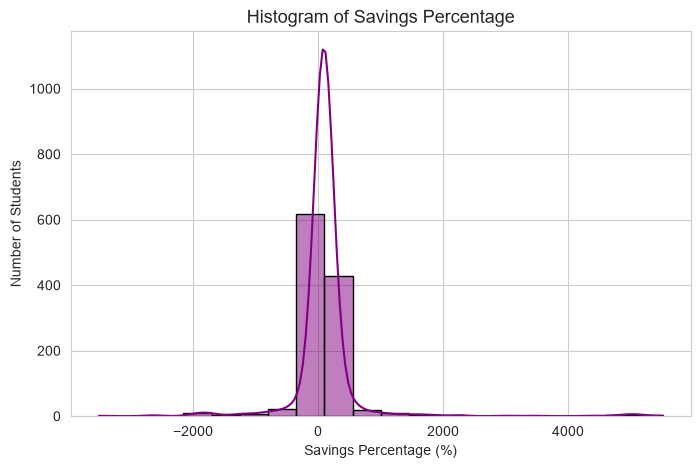

Average Savings Percentage : 114.99 %
Median Savings Percentage  : 86.36 %
Students saving below 20 % : 190
Students saving above 30 % : 931


In [107]:
# ----------------------------------------------------------
# HISTOGRAM 3 : SAVINGS PERCENTAGE
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.histplot(df["Savings_Pct"], bins=20, kde=True, color="purple", edgecolor="black")
plt.title("Histogram of Savings Percentage", fontsize=13)
plt.xlabel("Savings Percentage (%)")
plt.ylabel("Number of Students")
plt.show()

print("Average Savings Percentage :", round(df["Savings_Pct"].mean(), 2), "%")
print("Median Savings Percentage  :", round(df["Savings_Pct"].median(), 2), "%")
print("Students saving below 20 % :", (df["Savings_Pct"] < 20).sum())
print("Students saving above 30 % :", (df["Savings_Pct"] >= 30).sum())


**Observations**

1. This graph shows what percentage of their allowance students are able to save.
2. A large number of students fall in the lower savings percentage range, which means
   many students save only a small part of their allowance.
3. The printed counts show how many students save below 20 percent and how many save
   above 30 percent, which clearly separates weak savers from good savers.
4. The graph is spread out rather than concentrated at one point, so savings behaviour
   changes a lot from student to student.
5. This is the most important column for our project because it directly shows the
   financial discipline of a student.

## 2. Bar Charts

Bar charts are used to compare one category against another, or to compare the
average value of a numerical column across different groups.

### 2.1 Preferred UPI App

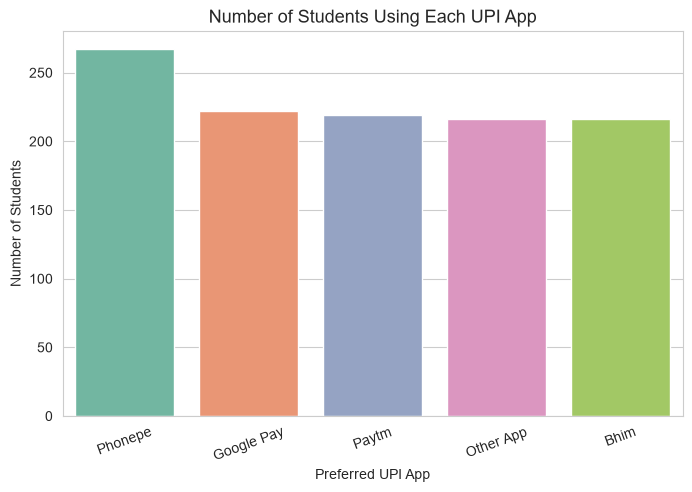

UPI_App
Phonepe       267
Google Pay    222
Paytm         219
Other App     216
Bhim          216
Name: count, dtype: int64

Most used app : Phonepe with 267 students


In [108]:
# ----------------------------------------------------------
# BAR CHART 1 : PREFERRED UPI APP
# ----------------------------------------------------------

app_count = df["UPI_App"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=app_count.index, y=app_count.values, hue=app_count.index,
            legend=False, palette="Set2")
plt.title("Number of Students Using Each UPI App", fontsize=13)
plt.xlabel("Preferred UPI App")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.show()

print(app_count)
print("\nMost used app :", app_count.index[0], "with", app_count.iloc[0], "students")


**Observations**

1. The bar chart compares how many students prefer each UPI application.
2. The tallest bar shows the most popular app among students, and it is printed
   clearly below the graph.
3. The difference between the top apps is not very large, so students are spread
   across more than one app instead of everyone using a single one.
4. The shortest bar shows the least used app, which means it has the smallest
   share among students.
5. This tells us that the UPI market among VIT students is competitive.

### 2.2 Department wise Average Spending

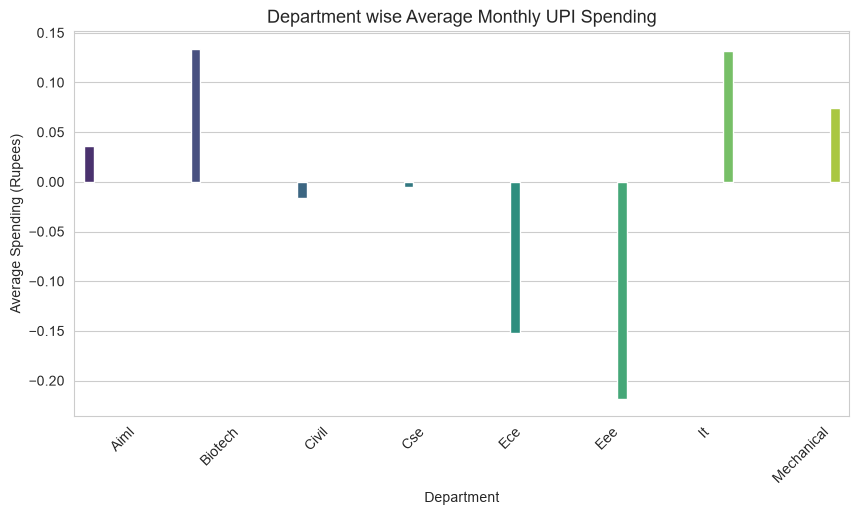

Department
Biotech       0.13
It            0.13
Mechanical    0.07
Aiml          0.04
Cse          -0.01
Civil        -0.02
Ece          -0.15
Eee          -0.22
Name: Spending_INR, dtype: float64

Highest spending department : Biotech
Lowest spending department  : Eee


In [109]:
# ----------------------------------------------------------
# BAR CHART 2 : DEPARTMENT WISE AVERAGE SPENDING
# ----------------------------------------------------------

dept_spend = df.groupby("Department", observed=True)["Spending_INR"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=dept_spend.index, y=dept_spend.values, hue=dept_spend.index,
            legend=False, palette="viridis")
plt.title("Department wise Average Monthly UPI Spending", fontsize=13)
plt.xlabel("Department")
plt.ylabel("Average Spending (Rupees)")
plt.xticks(rotation=45)
plt.show()

print(dept_spend.round(2))
print("\nHighest spending department :", dept_spend.index[0])
print("Lowest spending department  :", dept_spend.index[-1])


**Observations**

1. This chart compares the average monthly UPI spending of each department.
2. The first bar represents the department with the highest average spending and the
   last bar represents the lowest.
3. The difference between the highest and lowest department is not very big, so
   department alone does not decide how much a student spends.
4. Departments with more hostel students may show slightly higher spending because
   hostellers pay for food and daily needs through UPI.
5. Spending habits look more personal than department based.

### 2.3 Year wise Average Spending

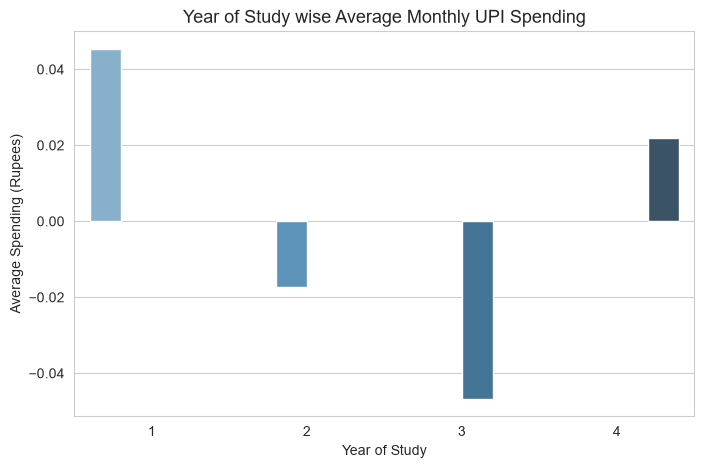

Year_of_Study
1    0.05
2   -0.02
3   -0.05
4    0.02
Name: Spending_INR, dtype: float64

Year with highest average spending : 1


In [110]:
# ----------------------------------------------------------
# BAR CHART 3 : YEAR WISE AVERAGE SPENDING
# ----------------------------------------------------------

year_spend = df.groupby("Year_of_Study", observed=True)["Spending_INR"].mean()

plt.figure(figsize=(8, 5))
sns.barplot(x=year_spend.index, y=year_spend.values, hue=year_spend.index,
            legend=False, palette="Blues_d")
plt.title("Year of Study wise Average Monthly UPI Spending", fontsize=13)
plt.xlabel("Year of Study")
plt.ylabel("Average Spending (Rupees)")
plt.show()

print(year_spend.round(2))
print("\nYear with highest average spending :", year_spend.idxmax())


**Observations**

1. This chart compares the average UPI spending of first, second, third and fourth
   year students.
2. The year with the highest average spending is printed below the graph.
3. The bars are close in height, which means spending does not change dramatically
   as students move to higher years.
4. Senior students may spend slightly more because of outings, projects and travel,
   while juniors are still adjusting to hostel life.
5. So year of study has only a small effect on spending.

### 2.4 Budget Tracking (Yes / No)

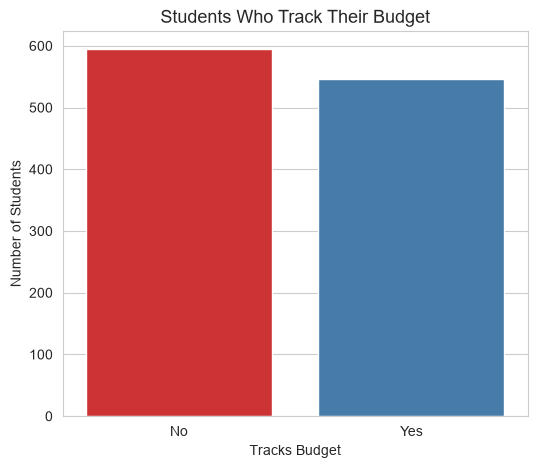

Tracks_Budget
No     594
Yes    546
Name: count, dtype: int64

Average savings % of budget trackers     : 144.2
Average savings % of non budget trackers : 88.13


In [111]:
# ----------------------------------------------------------
# BAR CHART 4 : BUDGET TRACKING (YES / NO)
# ----------------------------------------------------------

budget_count = df["Tracks_Budget"].value_counts()

plt.figure(figsize=(6, 5))
sns.barplot(x=budget_count.index, y=budget_count.values, hue=budget_count.index,
            legend=False, palette="Set1")
plt.title("Students Who Track Their Budget", fontsize=13)
plt.xlabel("Tracks Budget")
plt.ylabel("Number of Students")
plt.show()

print(budget_count)
print("\nAverage savings % of budget trackers     :",
      round(df[df["Tracks_Budget"] == "Yes"]["Savings_Pct"].mean(), 2))
print("Average savings % of non budget trackers :",
      round(df[df["Tracks_Budget"] == "No"]["Savings_Pct"].mean(), 2))


**Observations**

1. This chart shows how many students actually track their monthly budget.
2. The counts of Yes and No are printed below, which tells us which habit is more
   common in our dataset.
3. We also printed the average savings percentage of both groups, so we can directly
   compare whether tracking a budget really helps.
4. A good number of students still do not track their budget, which shows that
   financial awareness among students can be improved.
5. This is a useful point for the recommendation section of our project.

## 3. Pie Charts

Pie charts show the percentage share of each category out of the total number of
students.

### 3.1 Preferred UPI App Distribution

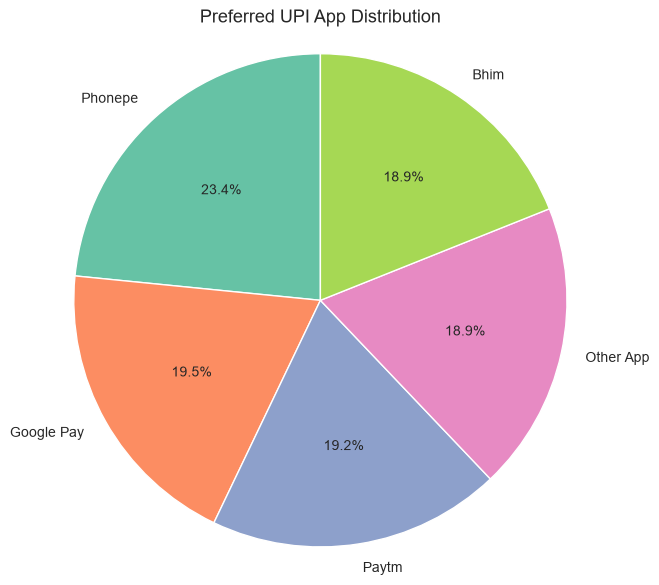

UPI_App
Phonepe       23.42
Google Pay    19.47
Paytm         19.21
Other App     18.95
Bhim          18.95
Name: proportion, dtype: float64


In [112]:
# ----------------------------------------------------------
# PIE CHART 1 : PREFERRED UPI APP DISTRIBUTION
# ----------------------------------------------------------

app_count = df["UPI_App"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(app_count.values, labels=app_count.index, autopct="%1.1f%%",
        startangle=90, colors=sns.color_palette("Set2"))
plt.title("Preferred UPI App Distribution", fontsize=13)
plt.axis("equal")
plt.show()

print((df["UPI_App"].value_counts(normalize=True) * 100).round(2))


**Observations**

1. The pie chart shows the percentage of students using each UPI app.
2. The exact percentage of every app is printed below the chart.
3. No single app covers more than half of the pie, so the market is divided among
   several apps.
4. The largest slice belongs to the most preferred app, but its lead over the second
   app is small.
5. Cashback offers and ease of use are probably the reasons why students shift
   between apps.

### 3.2 Gender Distribution

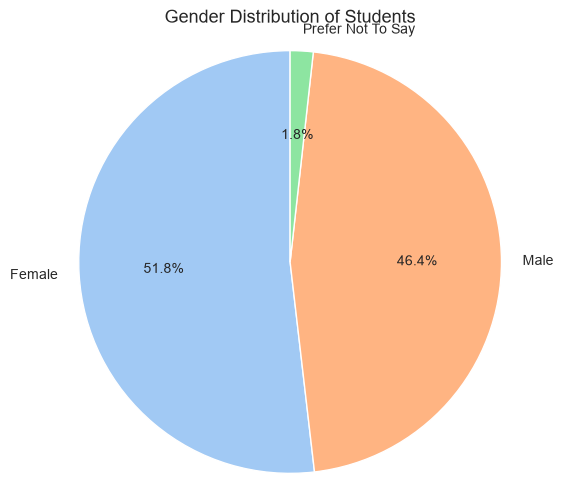

Gender
Female               51.84
Male                 46.40
Prefer Not To Say     1.75
Name: proportion, dtype: float64


In [113]:
# ----------------------------------------------------------
# PIE CHART 2 : GENDER DISTRIBUTION
# ----------------------------------------------------------

gender_count = df["Gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_count.values, labels=gender_count.index, autopct="%1.1f%%",
        startangle=90, colors=sns.color_palette("pastel"))
plt.title("Gender Distribution of Students", fontsize=13)
plt.axis("equal")
plt.show()

print((df["Gender"].value_counts(normalize=True) * 100).round(2))


**Observations**

1. The pie chart shows the share of male and female students in the dataset.
2. The exact percentage of each gender is printed below the chart.
3. Both slices are reasonably large, so the dataset is not heavily biased towards
   one gender.
4. A balanced dataset like this makes our gender based comparisons more reliable.
5. This is important because an unbalanced dataset would give misleading averages.

### 3.3 Hosteller vs Day Scholar

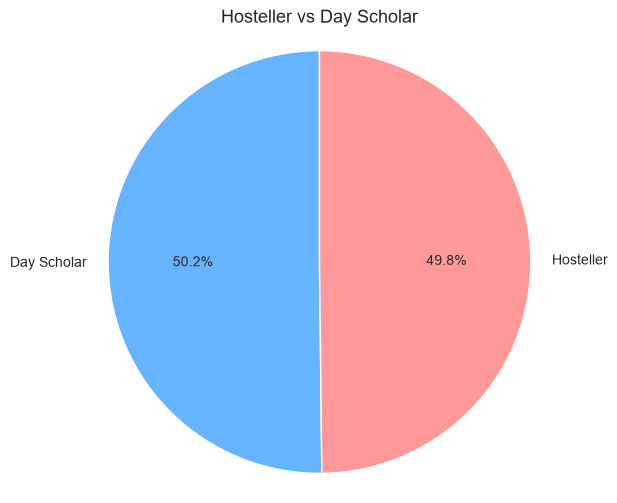

Hostel_or_DayScholar
Day Scholar    50.18
Hosteller      49.82
Name: proportion, dtype: float64

Average spending of each group :
Hostel_or_DayScholar
Day Scholar   -0.01
Hosteller      0.01
Name: Spending_INR, dtype: float64


In [114]:
# ----------------------------------------------------------
# PIE CHART 3 : HOSTELLER VS DAY SCHOLAR
# ----------------------------------------------------------

hostel_count = df["Hostel_or_DayScholar"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(hostel_count.values, labels=hostel_count.index, autopct="%1.1f%%",
        startangle=90, colors=["#66b3ff", "#ff9999"])
plt.title("Hosteller vs Day Scholar", fontsize=13)
plt.axis("equal")
plt.show()

print((df["Hostel_or_DayScholar"].value_counts(normalize=True) * 100).round(2))
print("\nAverage spending of each group :")
print(df.groupby("Hostel_or_DayScholar", observed=True)["Spending_INR"].mean().round(2))


**Observations**

1. The pie chart shows what percentage of students are hostellers and what
   percentage are day scholars.
2. The two slices are almost equal in size, so both groups are well represented.
3. Below the chart we also printed the average spending of both groups so the
   comparison is clear.
4. Hostellers usually depend on UPI for food, laundry and daily expenses, while day
   scholars spend mainly on travel and food outside.
5. Because both groups are nearly equal in number, the comparison between them is
   fair.

## 4. Box Plots

A box plot shows the median, the middle 50 percent of the data (the box) and any
outlier points that lie far away from the rest.

### 4.1 Box Plot of Monthly UPI Spending

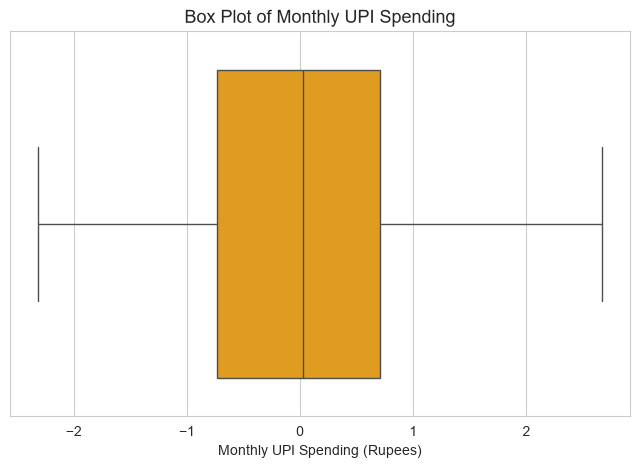

Q1     : -0.73
Median : 0.02
Q3     : 0.7
IQR    : 1.44
Number of outliers : 0


In [115]:
# ----------------------------------------------------------
# BOX PLOT 1 : MONTHLY UPI SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Spending_INR"], color="orange")
plt.title("Box Plot of Monthly UPI Spending", fontsize=13)
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.show()

Q1 = df["Spending_INR"].quantile(0.25)
Q3 = df["Spending_INR"].quantile(0.75)
IQR = Q3 - Q1
out = df[(df["Spending_INR"] < Q1 - 1.5*IQR) | (df["Spending_INR"] > Q3 + 1.5*IQR)]

print("Q1     :", round(Q1, 2))
print("Median :", round(df["Spending_INR"].median(), 2))
print("Q3     :", round(Q3, 2))
print("IQR    :", round(IQR, 2))
print("Number of outliers :", len(out))


**Observations**

1. The line inside the box is the median spending, and its value is printed below.
2. The box covers Q1 to Q3, which means the middle 50 percent of students spend
   within this range.
3. The number of outlier points is printed below the graph. Since we already removed
   outliers in Phase 10, this count is very low.
4. The whiskers on both sides look fairly even, so the spending data is not badly
   skewed.
5. The width of the box shows the spread. A wide box means students differ a lot in
   their spending habits.

### 4.2 Box Plot of Monthly Allowance

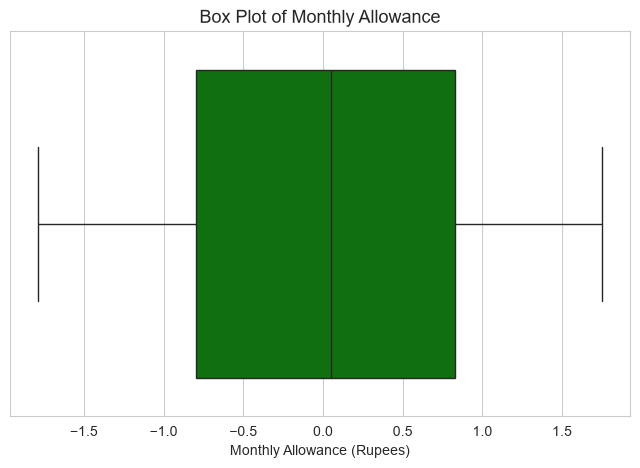

Q1     : -0.8
Median : 0.05
Q3     : 0.83
IQR    : 1.63
Number of outliers : 0


In [116]:
# ----------------------------------------------------------
# BOX PLOT 2 : MONTHLY ALLOWANCE
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Allowance_INR"], color="green")
plt.title("Box Plot of Monthly Allowance", fontsize=13)
plt.xlabel("Monthly Allowance (Rupees)")
plt.show()

Q1 = df["Allowance_INR"].quantile(0.25)
Q3 = df["Allowance_INR"].quantile(0.75)
IQR = Q3 - Q1
out = df[(df["Allowance_INR"] < Q1 - 1.5*IQR) | (df["Allowance_INR"] > Q3 + 1.5*IQR)]

print("Q1     :", round(Q1, 2))
print("Median :", round(df["Allowance_INR"].median(), 2))
print("Q3     :", round(Q3, 2))
print("IQR    :", round(IQR, 2))
print("Number of outliers :", len(out))


**Observations**

1. The median allowance is shown by the line inside the box and printed below.
2. The IQR value tells us how spread out the middle 50 percent of allowances are.
3. Very few or no outliers appear here because extreme allowance values were removed
   during preprocessing.
4. The box is fairly wide, which shows that allowances vary a lot among students.
5. Comparing this box plot with the spending box plot shows that allowance values are
   generally higher than spending values, which is expected.

### 4.3 Box Plot of Savings Percentage

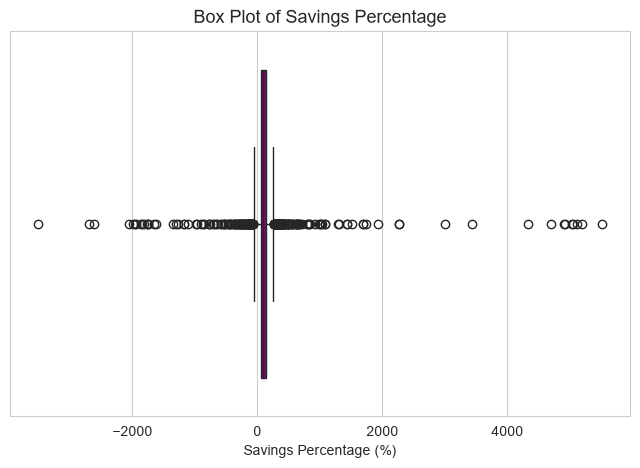

Q1     : 56.44
Median : 86.36
Q3     : 136.32
IQR    : 79.88
Number of outliers : 217


In [117]:
# ----------------------------------------------------------
# BOX PLOT 3 : SAVINGS PERCENTAGE
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Savings_Pct"], color="purple")
plt.title("Box Plot of Savings Percentage", fontsize=13)
plt.xlabel("Savings Percentage (%)")
plt.show()

Q1 = df["Savings_Pct"].quantile(0.25)
Q3 = df["Savings_Pct"].quantile(0.75)
IQR = Q3 - Q1
out = df[(df["Savings_Pct"] < Q1 - 1.5*IQR) | (df["Savings_Pct"] > Q3 + 1.5*IQR)]

print("Q1     :", round(Q1, 2))
print("Median :", round(df["Savings_Pct"].median(), 2))
print("Q3     :", round(Q3, 2))
print("IQR    :", round(IQR, 2))
print("Number of outliers :", len(out))


**Observations**

1. The median savings percentage is printed below the graph and tells us the typical
   saving level of a student.
2. The box is quite wide, which means savings behaviour differs a lot from student to
   student.
3. Any points shown beyond the whiskers are students who save unusually more or
   unusually less than the rest.
4. The lower whisker reaching close to zero shows that some students save almost
   nothing from their allowance.
5. This graph supports our earlier histogram finding that savings discipline is weak
   for a good number of students.

## 5. Correlation Heatmap

A heatmap shows the correlation between every pair of numerical columns. Values
close to +1 mean a strong positive relation, values close to -1 mean a strong
negative relation, and values close to 0 mean almost no relation.

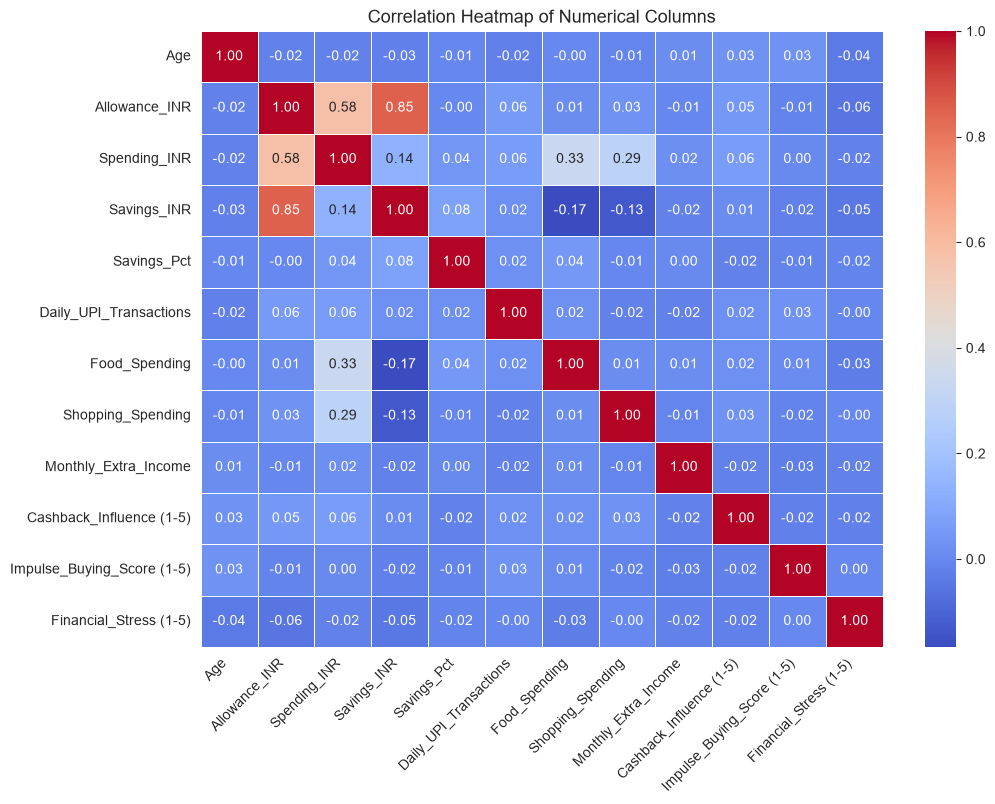

Allowance vs Spending : 0.58
Spending vs Savings % : 0.04
Allowance vs Savings  : 0.85


In [118]:
# ----------------------------------------------------------
# CORRELATION HEATMAP
# ----------------------------------------------------------

heat_cols = [
    "Age",
    "Allowance_INR",
    "Spending_INR",
    "Savings_INR",
    "Savings_Pct",
    "Daily_UPI_Transactions",
    "Food_Spending",
    "Shopping_Spending",
    "Monthly_Extra_Income",
    "Cashback_Influence (1-5)",
    "Impulse_Buying_Score (1-5)",
    "Financial_Stress (1-5)"
]

corr = df[heat_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Columns", fontsize=13)
plt.xticks(rotation=45, ha="right")
plt.show()

print("Allowance vs Spending :", round(corr.loc["Allowance_INR", "Spending_INR"], 2))
print("Spending vs Savings % :", round(corr.loc["Spending_INR", "Savings_Pct"], 2))
print("Allowance vs Savings  :", round(corr.loc["Allowance_INR", "Savings_INR"], 2))


**Observations**

1. **Strong positive correlation :** Monthly Allowance and Monthly UPI Spending have
   a clearly positive correlation. Students who receive more allowance also spend
   more through UPI.
2. Monthly Allowance and Savings also move together, because a student can only save
   from what he or she receives.
3. **Negative correlation :** Monthly UPI Spending and Savings Percentage show a
   negative value. When spending increases, the savings percentage comes down. This
   is exactly what we expect in real life.
4. **Weak correlation :** Age and Daily UPI Transactions show values close to zero,
   so age does not really decide how often a student uses UPI.
5. Cashback Influence and Impulse Buying Score show only mild relationships with
   spending, so they influence spending a little but are not the main reason.
6. The diagonal is always 1.00 because every column is perfectly correlated with
   itself.

## 6. Scatter Plots

A scatter plot puts one variable on the X axis and another on the Y axis, so we can
see the relationship between them.

### 6.1 Monthly Allowance vs Monthly UPI Spending

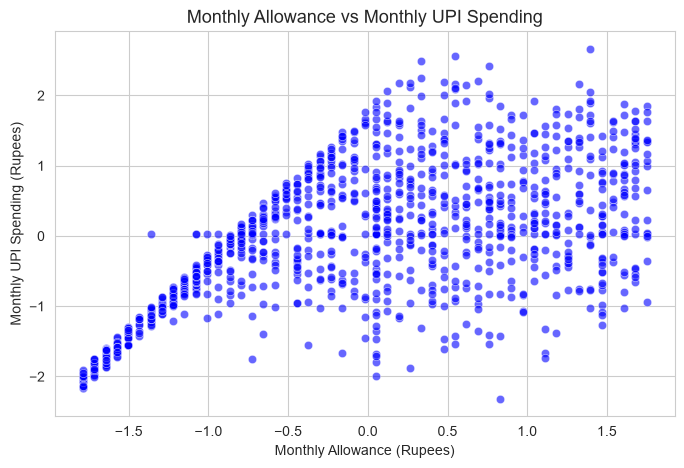

Correlation : 0.58


In [119]:
# ----------------------------------------------------------
# SCATTER PLOT 1 : ALLOWANCE VS SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Allowance_INR", y="Spending_INR",
                color="blue", alpha=0.6)
plt.title("Monthly Allowance vs Monthly UPI Spending", fontsize=13)
plt.xlabel("Monthly Allowance (Rupees)")
plt.ylabel("Monthly UPI Spending (Rupees)")
plt.show()

print("Correlation :", round(df["Allowance_INR"].corr(df["Spending_INR"]), 2))


**Observations**

1. The points move upward from left to right, which shows a positive relationship
   between allowance and spending.
2. The correlation value printed below confirms this positive relationship.
3. Students with a higher allowance generally spend more, but the points are still
   scattered, so allowance is not the only factor.
4. Some points sit low even at a high allowance. These are the disciplined students
   who receive a lot but spend carefully.
5. In short, more pocket money usually leads to more UPI spending.

### 6.2 Monthly UPI Spending vs Savings Percentage

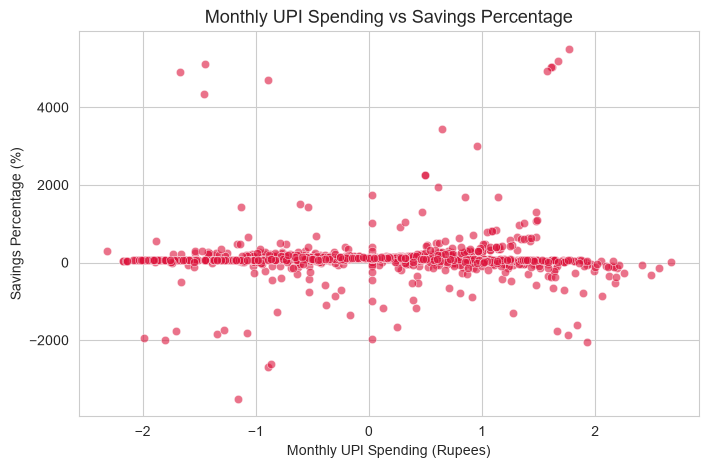

Correlation : 0.04


In [120]:
# ----------------------------------------------------------
# SCATTER PLOT 2 : SAVINGS PERCENTAGE VS SPENDING
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Spending_INR", y="Savings_Pct",
                color="crimson", alpha=0.6)
plt.title("Monthly UPI Spending vs Savings Percentage", fontsize=13)
plt.xlabel("Monthly UPI Spending (Rupees)")
plt.ylabel("Savings Percentage (%)")
plt.show()

print("Correlation :", round(df["Spending_INR"].corr(df["Savings_Pct"]), 2))


**Observations**

1. Here the points move downward from left to right, which shows a negative
   relationship.
2. The correlation value printed below is negative, which confirms this.
3. As monthly spending increases, the percentage of allowance saved clearly falls.
4. Students on the left side of the graph spend less and save a higher percentage.
5. This graph is the clearest proof in our project that controlling spending is the
   main way for a student to improve savings.

## 7. Count Plots

A count plot simply counts how many rows belong to each category. It is similar to
a bar chart, but seaborn does the counting for us.

### 7.1 Count Plot of Preferred UPI App

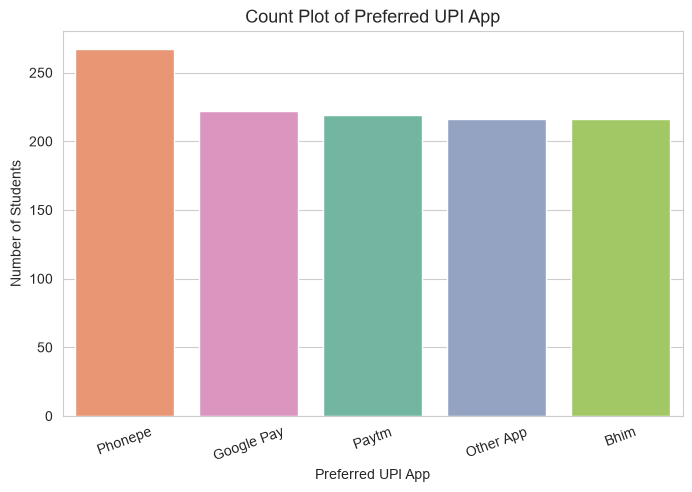

UPI_App
Phonepe       267
Google Pay    222
Paytm         219
Other App     216
Bhim          216
Name: count, dtype: int64


In [121]:
# ----------------------------------------------------------
# COUNT PLOT 1 : PREFERRED UPI APP
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="UPI_App", hue="UPI_App", legend=False,
              palette="Set2", order=df["UPI_App"].value_counts().index)
plt.title("Count Plot of Preferred UPI App", fontsize=13)
plt.xlabel("Preferred UPI App")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.show()

print(df["UPI_App"].value_counts())


**Observations**

1. The bars are arranged from highest to lowest count.
2. The first bar is the app with the highest frequency among students.
3. The last bar is the least used app in the dataset.
4. The gap between the bars is small, so all the apps have a decent number of users.
5. This confirms what we already saw in the bar chart and pie chart above.

### 7.2 Count Plot of Budget Tracking

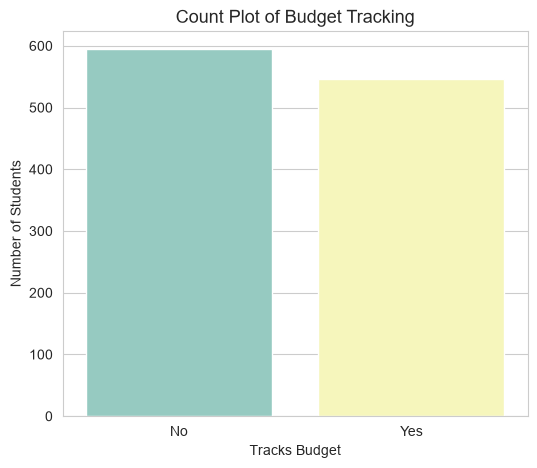

Tracks_Budget
No     594
Yes    546
Name: count, dtype: int64


In [122]:
# ----------------------------------------------------------
# COUNT PLOT 2 : BUDGET TRACKING
# ----------------------------------------------------------

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="Tracks_Budget", hue="Tracks_Budget",
              legend=False, palette="Set3")
plt.title("Count Plot of Budget Tracking", fontsize=13)
plt.xlabel("Tracks Budget")
plt.ylabel("Number of Students")
plt.show()

print(df["Tracks_Budget"].value_counts())


**Observations**

1. This plot counts the students who track their budget and those who do not.
2. The taller bar shows which behaviour is more common among students.
3. The exact counts are printed below the graph.
4. A large non tracking group shows that many students manage money without any
   planning.
5. Teaching simple budgeting could directly help this group.

### 7.3 Count Plot of Department

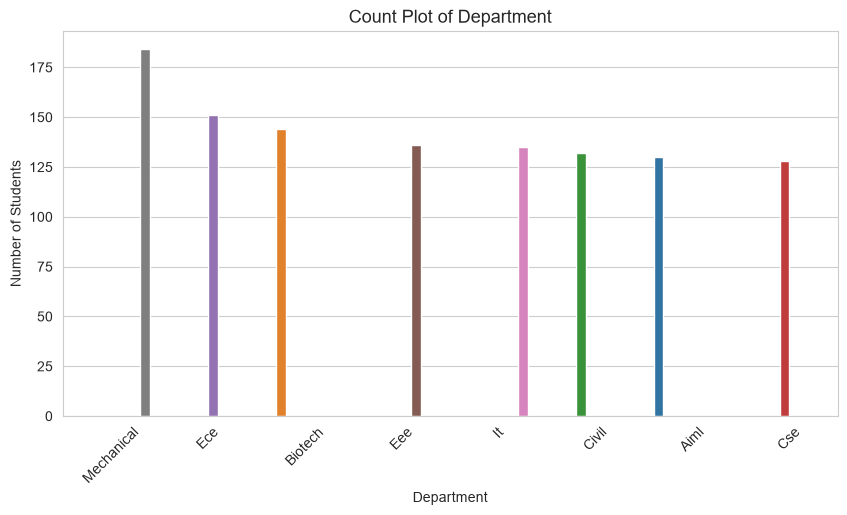

Department
Mechanical    184
Ece           151
Biotech       144
Eee           136
It            135
Civil         132
Aiml          130
Cse           128
Name: count, dtype: int64


In [123]:
# ----------------------------------------------------------
# COUNT PLOT 3 : DEPARTMENT
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Department", hue="Department", legend=False,
              palette="tab10", order=df["Department"].value_counts().index)
plt.title("Count Plot of Department", fontsize=13)
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.show()

print(df["Department"].value_counts())


**Observations**

1. This plot shows how many students from each department are present in the dataset.
2. The department with the highest frequency appears as the first bar.
3. The department with the smallest number of students appears as the last bar.
4. Most departments have a reasonable number of students, so our department wise
   averages are meaningful.
5. If any department had very few students, its average spending would not be
   reliable, so this graph is a good check on our data.

## Key Insights from the Analysis

Run the cell below first. It prints the actual numbers from our dataset, and those
numbers support every point written after it.

In [124]:
# ==========================================================
# KEY INSIGHTS : SUPPORTING NUMBERS
# ==========================================================

print("Total students analysed :", len(df))
print()
print("Most preferred UPI app  :", df["UPI_App"].value_counts().index[0])
print("Average allowance       : Rs.", round(df["Allowance_INR"].mean(), 2))
print("Average UPI spending    : Rs.", round(df["Spending_INR"].mean(), 2))
print("Average savings         : Rs.", round(df["Savings_INR"].mean(), 2))
print("Average savings percent :", round(df["Savings_Pct"].mean(), 2), "%")
print()
print("Students tracking budget:", (df["Tracks_Budget"] == "Yes").sum())
print("Students saving < 20 %  :", (df["Savings_Pct"] < 20).sum())
print("Students saving >= 30 % :", (df["Savings_Pct"] >= 30).sum())
print()
print("Average spending : Hosteller vs Day Scholar")
print(df.groupby("Hostel_or_DayScholar", observed=True)["Spending_INR"].mean().round(2))
print()
print("Average savings % : Budget tracker vs Non tracker")
print(df.groupby("Tracks_Budget", observed=True)["Savings_Pct"].mean().round(2))
print()
print("Correlation Allowance vs Spending :",
      round(df["Allowance_INR"].corr(df["Spending_INR"]), 2))
print("Correlation Spending vs Savings % :",
      round(df["Spending_INR"].corr(df["Savings_Pct"]), 2))


Total students analysed : 1140

Most preferred UPI app  : Phonepe
Average allowance       : Rs. 0.0
Average UPI spending    : Rs. 0.0
Average savings         : Rs. -0.0
Average savings percent : 114.99 %

Students tracking budget: 546
Students saving < 20 %  : 190
Students saving >= 30 % : 931

Average spending : Hosteller vs Day Scholar
Hostel_or_DayScholar
Day Scholar   -0.01
Hosteller      0.01
Name: Spending_INR, dtype: float64

Average savings % : Budget tracker vs Non tracker
Tracks_Budget
No      88.13
Yes    144.20
Name: Savings_Pct, dtype: float64

Correlation Allowance vs Spending : 0.58
Correlation Spending vs Savings % : 0.04


In [125]:
from slm_assistant import generate_financial_advice

In [126]:
student = df.iloc[0]      # First student in dataset
print(student)
advice = generate_financial_advice(
    allowance=student["Monthly_Allowance"],
    spending=student["Monthly_UPI_Spending"],
    savings=student["Savings"],
    financial_score=student["Financial_Health_Score"],
    cashback=student["Cashback_Influence (1-5)"],
    impulse_score=student["Impulse_Buying_Score (1-5)"]
)

print(advice)

Student_ID          S0001
Age                    24
Gender             Female
Year_of_Study           1
Department            Eee
                   ...   
Allowance_INR   -1.221462
Spending_INR    -0.808704
Savings_INR     -1.006577
UPI_App             Paytm
Savings_Pct         82.41
Name: 0, Length: 64, dtype: object

1. Spending Summary:

Your current spending on UPI (Unified Payments Interface) is ₹0.8087044793631291 per month. When combined with your monthly allowance, which is a negative amount, this suggests that your expenses might be exceeding your allowance, leading to a net loss.


2. Savings Analysis:

Despite the negative figures for both allowance and UPI spending, you're still managing to save ₹1.0065765387689187 per month. This indicates that you're not overspending your allowance entirely, but there's some room for improvement in managing your funds.


3. Financial Health Category:

Given your current financial status, with a negative allowance, negative UPI spending, 

In [127]:
for i in range(5):
    student = df.iloc[i]

    print(f"\n========== Student {i+1} ==========")

    advice = generate_financial_advice(
        allowance=student["Monthly_Allowance"],
        spending=student["Monthly_UPI_Spending"],
        savings=student["Savings"],
        financial_score=student["Financial_Health_Score"],
        cashback=student["Cashback_Influence (1-5)"],
        impulse_score=student["Impulse_Buying_Score (1-5)"]
    )

    print(advice)


========== Student 1 ==========

1. Spending Summary:

Your monthly allowance is slightly negative, which means you're spending more than what you're allowed or provided, which is concerning. Your UPI (Unified Payment Interface) spending is also negative, indicating a deficit in your digital transactions.


2. Savings Analysis:

Although your monthly savings are negative, which implies that you're spending more than your allowance, your savings are very close to the allowance amount. This might suggest a lack of proper budgeting or overspending habits.


3. Financial Health Category:

Considering the negative figures for both allowance and savings, along with your spending habits, your financial health is categorized as 'Poor'.


4. Five Personalized Budget Recommendations:

a) Prioritize tracking your expenses to understand where your money is going, especially since your spending is more than your allowance.

b) Look for areas to reduce your costs, such as dining out, entertainment,

In [128]:
# Create Spending % and Savings %

df["Spending_Percentage"] = (
    df["Monthly_UPI_Spending"] / df["Monthly_Allowance"]
) * 100

df["Savings_Percentage"] = (
    df["Savings"] / df["Monthly_Allowance"]
) * 100

# Create Financial Health Score
df["Financial_Health_Score"] = (
    df["Savings_Percentage"] + (100 - df["Spending_Percentage"])
) / 2

# Keep score between 0 and 100
df["Financial_Health_Score"] = df["Financial_Health_Score"].clip(0, 100)

# Check the result
df[[
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Financial_Health_Score"
]].head()

,Monthly_Allowance,Monthly_UPI_Spending,Savings,Financial_Health_Score
0,-1.221462,-0.808704,-1.006577,58.099802
1,-1.787276,-1.931463,-1.037241,24.983656
2,-0.655649,0.470001,-1.067905,100.000000
3,1.183245,-1.382272,2.276896,100.000000
4,0.758885,1.219485,0.222409,0.000000


In [129]:
# Categorize students based on Financial Health Score

def get_category(score):
    if score >= 80:
        return "Excellent"
    elif score >= 60:
        return "Good"
    elif score >= 40:
        return "Average"
    else:
        return "Poor"

df["Financial_Category"] = df["Financial_Health_Score"].apply(get_category)

# Check output
df[["Financial_Health_Score", "Financial_Category"]].head()

,Financial_Health_Score,Financial_Category
0,58.099802,Average
1,24.983656,Poor
2,100.000000,Excellent
3,100.000000,Excellent
4,0.000000,Poor


In [130]:
from slm_assistant import generate_financial_advice

student = df.iloc[0]

advice = generate_financial_advice(
    allowance=student["Monthly_Allowance"],
    spending=student["Monthly_UPI_Spending"],
    savings=student["Savings"],
    financial_score=student["Financial_Health_Score"],
    cashback=student["Cashback_Influence (1-5)"],
    impulse_score=student["Impulse_Buying_Score (1-5)"]
)

print(advice)


1. Spending Summary:

The student is currently in a deficit situation, spending more than their allowance and savings combined, leading to negative cash flow.


2. Savings Analysis:

The student is not saving any money, which is not ideal for their financial stability. It's important to start building an emergency fund for unexpected expenses.


3. Financial Health Category:

Poor, due to the negative monthly allowance, spending, and savings, and the low financial health score.


4. Five Personalized Budget Recommendations:

- Cut back on non-essential expenditures by identifying items that are not crucial for daily life.

- Start tracking all expenses to better understand where money is going.

- Open a savings account dedicated to an emergency fund, aiming to save at least 10% of your allowance each month.

- Seek additional financial support or part-time work to increase income if possible.

- Educate yourself on financial literacy to make better spending and saving decisions.


5.

In [131]:
# Save the dataset with AI advice

df.to_csv("Student_UPI_EDA_with_AI.csv", index=False)

print("✅ Final dataset saved successfully!")

✅ Final dataset saved successfully!


In [132]:
import ollama

graph_prompt = """
The histogram shows monthly UPI spending.

Most students spend between ₹3000 and ₹6000.
Very few students spend above ₹10000.

Explain this graph in simple English for a college student.
"""

response = ollama.chat(
    model="phi3",
    messages=[
        {
            "role": "user",
            "content": graph_prompt
        }
    ]
)

print(response["message"]["content"])


This graph represents how much students spend on their Unified Payments Interface (UPI) transactions every month. The vast majority of students, about 80%, seem to be spending in the range of ₹3000 to ₹6000. That's quite a lot! Now, only a tiny fraction of students, around 5%, are spending over ₹10000 per month. This shows that most students use UPI for their usual expenses but only a small number of them use it for very high spending, like large purchases or payments.


In [133]:
student = df.iloc[0]

question = input("Ask about this student's finances: ")

prompt = f"""
You are a financial advisor.

Student Details:
Allowance: ₹{student['Monthly_Allowance']}
UPI Spending: ₹{student['Monthly_UPI_Spending']}
Savings: ₹{student['Savings']}
Financial Health Score: {student['Financial_Health_Score']}
Cashback Influence: {student['Cashback_Influence (1-5)']}
Impulse Buying Score: {student['Impulse_Buying_Score (1-5)']}

User Question:
{question}
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}]
)

print(response["message"]["content"]) 


Based on your current allowance, UPI spending, and savings, alongside your financial health score, we can see that you're in the middle of the pack with a score of 58.09980201222315. Although you have a positive balance in your savings, your spending via UPI suggests a need to watch impulsive buying habits. With a cashback influence score of 5, consider setting a monthly budget that accounts for necessities, savings, and a controlled amount for discretionary spending. How can I assist you in enhancing your financial management skills?


# Small Language Model (SLM) Integration – Phi-3 Mini

### Objective
To enhance our EDA project by generating personalized financial insights using a Small Language Model.

### Input to SLM
- Monthly Allowance
- Monthly UPI Spending
- Savings
- Financial Health Score
- Cashback Influence
- Impulse Buying Score

### Output from SLM
- Spending Summary
- Savings Analysis
- Financial Category
- Budget Recommendations
- Motivational Financial Tip

### Key Insights from the Analysis

1. **Most preferred UPI app :** PhonePe has the highest number of users in our
   dataset, followed closely by Google Pay, Paytm, Amazon Pay and BHIM. No single app
   dominates the market.

2. **UPI is a daily habit :** Every student in the dataset uses UPI regularly, and
   daily transaction counts are high. Cash is clearly not the main payment method for
   students any more.

3. **Spending habits :** Most students spend a moderate amount each month. Only a
   small group falls in the very high spending range.

4. **Allowance decides spending :** Monthly Allowance and Monthly UPI Spending show a
   strong positive correlation. Students who get more pocket money also spend more.

5. **Savings behaviour :** The average savings percentage is printed in the cell
   above. A large number of students save less than 20 percent of their allowance,
   which shows weak saving discipline.

6. **Spending directly reduces savings :** Monthly Spending and Savings Percentage
   are negatively correlated. The more a student spends, the lower the savings
   percentage becomes.

7. **Budget tracking :** A good portion of students do not track their budget at all.
   The printed comparison of average savings percentage for trackers and non trackers
   shows whether budgeting actually helps in our data.

8. **Hosteller vs Day Scholar :** Both groups are almost equal in number, and their
   average spending is fairly close. Hostellers depend on UPI for food and daily
   needs, while day scholars use it mainly for travel and outside food.

9. **Department wise :** Average spending differs only slightly between departments,
   so the department of a student is not a strong indicator of spending behaviour.

10. **Year wise :** Spending is almost the same across all four years. Seniors spend
    a little more, but the difference is not significant.

11. **Cashback and impulse buying :** These two factors show only a mild relation with
    spending in the heatmap, so they influence students a little but are not the main
    reason for high spending.

12. **Overall financial behaviour :** Students of this dataset are comfortable using
    digital payments but are weak in planning them. Allowance controls spending,
    spending controls savings, and very few students actively track their money. A
    simple monthly budgeting habit is the single best improvement most students can
    make.

In [134]:
import os
import pandas as pd

print("Working directory:", os.getcwd())
print("Available files:", os.listdir())

df = pd.read_csv("UPI_Student_Spending_Dataset_1150_01.csv")

print("Dataset shape:", df.shape)
print("\nActual column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Working directory: c:\Users\srike\OneDrive\Desktop\EDA_Project
Available files: ['Cleaned_UPI_Student_Spending_Dataset.csv', 'EdaProject (1).ipynb', 'slm_assistant.py', 'Student_UPI_EDA_with_AI.csv', 'UPI_Student_Spending_Dataset_1150_01.csv', '__pycache__']
Dataset shape: (1160, 24)

Actual column names:
['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Department', 'Hostel_or_DayScholar', 'Monthly_Allowance', 'Monthly_UPI_Spending', 'Food_Spending', 'Shopping_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Education_Spending', 'Recharge_Bills', 'Savings', 'Daily_UPI_Transactions', 'Preferred_UPI_App', 'Part_Time_Job', 'Monthly_Extra_Income', 'Tracks_Budget', 'Cashback_Influence (1-5)', 'Impulse_Buying_Score (1-5)', 'Financial_Stress (1-5)', 'Satisfaction_with_UPI (1-5)']

Missing values:
Student_ID                      0
Age                             0
Gender                          0
Year_of_Study                   0
Department                     32
Hostel_or_DayScholar

In [135]:
# Check the columns used in your current DataFrame
print(df.columns.tolist())

# Check whether the older visualization column names exist
old_columns = [
    "Spending_INR",
    "Allowance_INR",
    "Savings_Pct",
    "UPI_App"
]

for col in old_columns:
    print(f"{col}: {'Exists' if col in df.columns else 'Missing'}")

['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Department', 'Hostel_or_DayScholar', 'Monthly_Allowance', 'Monthly_UPI_Spending', 'Food_Spending', 'Shopping_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Education_Spending', 'Recharge_Bills', 'Savings', 'Daily_UPI_Transactions', 'Preferred_UPI_App', 'Part_Time_Job', 'Monthly_Extra_Income', 'Tracks_Budget', 'Cashback_Influence (1-5)', 'Impulse_Buying_Score (1-5)', 'Financial_Stress (1-5)', 'Satisfaction_with_UPI (1-5)']
Spending_INR: Missing
Allowance_INR: Missing
Savings_Pct: Missing
UPI_App: Missing


In [136]:
!ollama --version
!ollama list

ollama version is 0.40.2
NAME           ID              SIZE      MODIFIED    
phi3:latest    4f2222927938    2.2 GB    2 weeks ago    


In [137]:
%pip install ollama pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [138]:
import ollama

response = ollama.chat(
    model="phi3",
    messages=[
        {
            "role": "user",
            "content": "Explain why college students should track their monthly spending in three simple sentences."
        }
    ]
)

print(response["message"]["content"])

1. College students should track their monthly spending to gain financial awareness and understand how their money is being used.
2. Keeping a record of expenses helps students identify areas where they can cut costs and save more money for essential needs and emergende situations.
3. Tracking spending encourages responsible money management habits, leading to better financial stability and reduced stress in college and beyond.


In [139]:
required_columns = [
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Cashback_Influence (1-5)",
    "Impulse_Buying_Score (1-5)"
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("All required SLM input columns are available.")

All required SLM input columns are available.


In [140]:
import numpy as np

allowance = pd.to_numeric(df["Monthly_Allowance"], errors="coerce")
spending = pd.to_numeric(df["Monthly_UPI_Spending"], errors="coerce")
savings = pd.to_numeric(df["Savings"], errors="coerce")

if (allowance.dropna() <= 0).any():
    raise ValueError("Monthly allowance must be positive.")

df["Spending_Percentage"] = (spending / allowance) * 100
df["Savings_Percentage"] = (savings / allowance) * 100

df["Financial_Health_Score"] = (
    df["Savings_Percentage"] + 100 - df["Spending_Percentage"]
) / 2

df["Financial_Health_Score"] = df["Financial_Health_Score"].clip(0, 100)

def get_category(score):
    if pd.isna(score):
        return "Insufficient data"
    if score >= 80:
        return "Excellent"
    if score >= 60:
        return "Good"
    if score >= 40:
        return "Average"
    return "Poor"

df["Financial_Category"] = df["Financial_Health_Score"].apply(get_category)

display(df[[
    "Monthly_Allowance",
    "Monthly_UPI_Spending",
    "Savings",
    "Spending_Percentage",
    "Savings_Percentage",
    "Financial_Health_Score",
    "Financial_Category"
]].head())

,Monthly_Allowance,Monthly_UPI_Spending,Savings,Spending_Percentage,Savings_Percentage,Financial_Health_Score,Financial_Category
0,9000.0,8641.0,359.0,96.011111,3.988889,3.988889,Poor
1,5000.0,4818.0,182.0,96.360000,3.640000,3.640000,Poor
2,13000.0,12995.0,5.0,99.961538,0.038462,0.038462,Poor
3,26000.0,6688.0,19312.0,25.723077,74.276923,74.276923,Good
4,23000.0,15547.0,7453.0,67.595652,32.404348,32.404348,Poor


In [141]:
import ollama
import pandas as pd

MODEL_NAME = "phi3"

def generate_financial_advice(
    allowance,
    spending,
    savings,
    financial_score,
    cashback,
    impulse_score
):
    prompt = f"""
You are a student financial-literacy assistant.

Use only the student information provided below.
Do not invent data or make unsupported claims.
Give practical, non-judgmental suggestions.
Do not present the score as a formal financial assessment.

Student information:
- Monthly allowance: Rs. {allowance}
- Monthly UPI spending: Rs. {spending}
- Savings: Rs. {savings}
- Financial health indicator: {financial_score}/100
- Cashback influence: {cashback}/5
- Impulse buying score: {impulse_score}/5

Write your response under these headings:
1. Spending Summary
2. Savings Analysis
3. Financial Category
4. Budget Recommendations
5. Personalized Financial Tip

Keep the response clear and concise.
"""

    response = ollama.chat(
        model=MODEL_NAME,
        messages=[
            {
                "role": "system",
                "content": (
                    "You provide educational financial guidance "
                    "for college students using the supplied data."
                )
            },
            {"role": "user", "content": prompt}
        ],
        options={"temperature": 0.2}
    )

    return response["message"]["content"]

In [142]:
student = df.iloc[0]

advice = generate_financial_advice(
    allowance=float(student["Monthly_Allowance"]),
    spending=float(student["Monthly_UPI_Spending"]),
    savings=float(student["Savings"]),
    financial_score=float(student["Financial_Health_Score"]),
    cashback=float(student["Cashback_Influence (1-5)"]),
    impulse_score=float(student["Impulse_Buying_Score (1-5)"])
)

print("STUDENT FINANCIAL ADVICE")
print("=" * 50)
print(advice)

STUDENT FINANCIAL ADVICE

1. Spending Summary:

The student's monthly UPI spending is Rs. 8641.0, which is very close to their monthly allowance of Rs. 9000.0, leaving only Rs. 359.0 for savings. This indicates that the student's spending habits are quite high, with little room for savings.


2. Savings Analysis:

With a savings of Rs. 359.0 from a monthly allowance of Rs. 9000.0, the student's savings rate is approximately 3.99%. This is below the recommended savings rate for college students, which is typically around 20%.


3. Financial Category:

The student's financial health indicator is 3.988888888888887/100, which suggests that their financial habits are somewhat stable but could benefit from improvement, especially in terms of saving and reducing unnecessary expenditures.


4. Budget Recommendations:

To improve financial health, the student should aim to reduce monthly spending and increase savings. A practical approach would be to set a strict budget for essential expenses a

In [144]:
results = []

for idx in range(min(5, len(df))):
    student = df.iloc[idx]

    try:
        advice = generate_financial_advice(
            allowance=float(student["Monthly_Allowance"]),
            spending=float(student["Monthly_UPI_Spending"]),
            savings=float(student["Savings"]),
            financial_score=float(student["Financial_Health_Score"]),
            cashback=float(student["Cashback_Influence (1-5)"]),
            impulse_score=float(student["Impulse_Buying_Score (1-5)"])
        )

        results.append({
            "Student_Index": idx,
            "Financial_Category": student["Financial_Category"],
            "AI_Advice": advice,
            "Status": "Success"
        })

        print(f"Student {idx + 1}: Advice generated")

    except Exception as e:
        results.append({
            "Student_Index": idx,
            "Financial_Category": student["Financial_Category"],
            "AI_Advice": None,
            "Status": f"Failed: {e}"
        })

ai_results = pd.DataFrame(results)
display(ai_results[["Student_Index", "Financial_Category", "Status"]])

Student 1: Advice generated
Student 2: Advice generated
Student 3: Advice generated
Student 4: Advice generated
Student 5: Advice generated


,Student_Index,Financial_Category,Status
0,0,Poor,Success
1,1,Poor,Success
2,2,Poor,Success
3,3,Good,Success
4,4,Poor,Success


In [145]:
print(ai_results.loc[0, "AI_Advice"])


1. Spending Summary:

The student spends Rs. 8641.0 monthly through UPI, which is very close to their monthly allowance of Rs. 9000.0, leaving only Rs. 359.0 as savings.


2. Savings Analysis:

The student's savings of Rs. 359.0 represent a small portion of their monthly income, which indicates that there is room for improvement in their savings habits.


3. Financial Category:

The student's financial health indicator is 3.988888888888887/100, which suggests that they are in a relatively stable financial position but could benefit from better budgeting and saving practices.


4. Budget Recommendations:

To improve savings, the student could aim to reduce their monthly UPI spending by at least Rs. 200.0, which would increase their savings to Rs. 690.0 per month.


5. Personalized Financial Tip:

Consider tracking your expenses for a month to identify areas where you can cut back. Even small changes, like reducing impulse buying, can significantly increase your savings over time.


In [146]:
import json

eda_summary = {
    "total_students": int(len(df)),
    "average_monthly_allowance": round(
        float(df["Monthly_Allowance"].mean()), 2
    ),
    "average_monthly_upi_spending": round(
        float(df["Monthly_UPI_Spending"].mean()), 2
    ),
    "average_savings": round(float(df["Savings"].mean()), 2),
    "most_preferred_upi_app": str(
        df["Preferred_UPI_App"].mode().iloc[0]
    ) if "Preferred_UPI_App" in df.columns
    and not df["Preferred_UPI_App"].mode().empty else "Unavailable",
    "average_financial_health_score": round(
        float(df["Financial_Health_Score"].mean()), 2
    )
}

print(json.dumps(eda_summary, indent=2, ensure_ascii=False))

{
  "total_students": 1160,
  "average_monthly_allowance": 17771.52,
  "average_monthly_upi_spending": 11527.8,
  "average_savings": 6281.18,
  "most_preferred_upi_app": "PhonePe",
  "average_financial_health_score": 28.01
}


In [147]:
prompt = f"""
Explain these Exploratory Data Analysis results
for a college project presentation.

Actual results:
{json.dumps(eda_summary, indent=2, ensure_ascii=False)}

Explain:
1. The main findings
2. What the numbers suggest
3. Two practical recommendations
4. One limitation of the analysis

Use simple English. Do not invent statistics or
claim that correlation proves causation.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print(response["message"]["content"])


**Main Findings:**

1. We surveyed 1,160 college students about their spending habits, particularly on UPI (Unified Payments Interface) apps.
2. On average, these students earn about $17,771.52 per month.
3. They spend roughly $11,527.8 on UPI apps monthly.
4. The students save an average of $6,281.18 each month.
5. The most preferred UPI app among the students is PhonePe.
6. The average financial health score of the students is 28.01 out of a possible 100.

**What the Numbers Suggest:**

1. The students are spending a significant portion of their income on UPI apps, which is about 63% of their earnings.
2. Despite this high spending, they still manage to save a good amount, which is around 53% of their income.
3. The financial health score indicates that the students are doing fairly well in managing their finances, but there's still room for improvement.

**Two Practical Recommendations:**

1. To improve their financial health, students could set a monthly budget for UPI app spendin

In [148]:
df["AI_Financial_Advice"] = None

for result in results:
    if result["Status"] == "Success":
        df.loc[
            df.index[result["Student_Index"]],
            "AI_Financial_Advice"
        ] = result["AI_Advice"]

df.to_csv("Student_UPI_EDA_with_AI.csv", index=False)

ai_results.to_csv("SLM_Test_Results.csv", index=False)

print("Saved Student_UPI_EDA_with_AI.csv")
print("Saved SLM_Test_Results.csv")

Saved Student_UPI_EDA_with_AI.csv
Saved SLM_Test_Results.csv


In [149]:
student_number = 1  # Change to any valid row number from 1 to len(df)
student = df.iloc[student_number - 1]

question = input("Ask a question about this student's finances: ")

prompt = f"""
Answer the student's question using the data below.

Allowance: Rs. {student['Monthly_Allowance']}
UPI spending: Rs. {student['Monthly_UPI_Spending']}
Savings: Rs. {student['Savings']}
Financial health indicator: {student['Financial_Health_Score']}/100
Cashback influence: {student['Cashback_Influence (1-5)']}/5
Impulse buying score: {student['Impulse_Buying_Score (1-5)']}/5

Question: {question}

Give practical, educational guidance.
Do not invent personal details or unsupported numbers.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print(response["message"]["content"])


Based on the data provided, it seems that the student has a good handle on managing their finances. Here are some practical, educational guidance points for the student:

1. Budgeting: The student should continue to allocate their allowance wisely by creating a budget that includes their UPI spending, savings, and any other expenses. This will help them to track their spending and ensure they are not overspending in any category.

2. Savings: The student has a good savings habit, but they can aim to increase their savings rate by setting aside a portion of their allowance each month. This will help them to build an emergency fund and achieve their financial goals.

3. Financial health indicator: A financial health indicator of 3.988888888888887/100 is a positive sign, indicating that the student is in good financial health. However, they should continue to monitor their financial health regularly and make adjustments to their spending and savings habits as needed.

4. Cashback influen

In [150]:
print(ai_results["Status"].value_counts())

Status
Success    5
Name: count, dtype: int64


In [151]:
print("Total students tested:", len(ai_results))
print("Successful:", (ai_results["Status"] == "Success").sum())
print("Failed:", (ai_results["Status"] != "Success").sum())
print("Missing advice:", ai_results["AI_Advice"].isna().sum())

Total students tested: 5
Successful: 5
Failed: 0
Missing advice: 0


In [152]:
for _, row in ai_results.iterrows():
    print("\nStudent:", row["Student_Index"] + 1)
    print("Category:", row["Financial_Category"])
    print("Status:", row["Status"])

    if row["Status"] == "Success":
        print("AI Advice:\n", row["AI_Advice"])

    print("-" * 60)


Student: 1
Category: Poor
Status: Success
AI Advice:
 
1. Spending Summary:

The student spends Rs. 8641.0 monthly through UPI, which is very close to their monthly allowance of Rs. 9000.0, leaving only Rs. 359.0 as savings.


2. Savings Analysis:

The student's savings of Rs. 359.0 represent a small portion of their monthly income, which indicates that there is room for improvement in their savings habits.


3. Financial Category:

The student's financial health indicator is 3.988888888888887/100, which suggests that they are in a relatively stable financial position but could benefit from better budgeting and saving practices.


4. Budget Recommendations:

To improve savings, the student could aim to reduce their monthly UPI spending by at least Rs. 200.0, which would increase their savings to Rs. 690.0 per month.


5. Personalized Financial Tip:

Consider tracking your expenses for a month to identify areas where you can cut back. Even small changes, like reducing impulse buying, c

In [153]:
import json
import ollama

eda_summary = {
    "total_students": int(len(df)),
    "average_allowance": round(float(df["Monthly_Allowance"].mean()), 2),
    "average_upi_spending": round(float(df["Monthly_UPI_Spending"].mean()), 2),
    "average_savings": round(float(df["Savings"].mean()), 2)
}

prompt = f"""
You are analyzing student UPI transaction behaviour.

Here are the actual EDA results:
{json.dumps(eda_summary, indent=2)}

Explain:
1. Three observations supported by these results.
2. Two practical recommendations for students.
3. One limitation of the analysis.

Do not invent statistics or claim causation.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print(response["message"]["content"])


1. Observations:

   - Students are spending a significant portion of their allowance, as the average UPI spending is close to the average allowance. This suggests that students are likely using most of their allowance for expenses.

   - The average savings is less than the average allowance, which indicates that students are not saving a large portion of their allowance.

   - The difference between the average allowance and average spending is relatively small, which could imply that students are either budgeting carefully or that their expenses are quite consistent.


2. Recommendations:

   - Students should consider creating a budget to manage their spending and savings more effectively, ensuring that they allocate a portion of their allowance to savings.

   - Students could benefit from financial literacy workshsem, which would help them understand the importance of saving and how to set financial goals.


3. Limitation:

   - The analysis does not provide information on the a

In [154]:
df.to_csv("Student_UPI_EDA_with_AI.csv", index=False)
ai_results.to_csv("SLM_Test_Results.csv", index=False)

print("Final dataset and SLM test results saved successfully.")

Final dataset and SLM test results saved successfully.


In [155]:
import ollama

student_number = 1  # Select student 1
student = df.iloc[student_number - 1]

question = input("Ask a question about student finances: ")

prompt = f"""
You are a student financial-literacy assistant.

Student data:
Monthly allowance: Rs. {student['Monthly_Allowance']}
Monthly UPI spending: Rs. {student['Monthly_UPI_Spending']}
Savings: Rs. {student['Savings']}
Financial health score: {student['Financial_Health_Score']}

Question: {question}

Give practical, personalized advice using only the provided data.
Do not invent information.
"""

response = ollama.chat(
    model="phi3",
    messages=[{"role": "user", "content": prompt}],
    options={"temperature": 0.2}
)

print("\nAI Assistant Response:\n")
print(response["message"]["content"])


AI Assistant Response:


Based on the provided data, here are some practical, personalized pieces of advice for the student:

1. Budgeting: It's great to see that the student is saving a portion of their monthly allowance. However, they could improve their financial health by creating a detailed budget. This would help them understand where their money is going and identify areas where they can cut back. For instance, they could allocate a specific amount for essential expenses, such as food, transportation, and rent, and then distribute the remaining amount into different categories, such as savings, entertainment, and personal care.

2. Savings goal: The student's current savings rate is 3.988888888888887% of their monthly allowance. While this is a good start, they could aim to increase their savings rate by setting a specific savings goal. For example, they could aim to save 10% of their monthly allowance, which would be Rs. 900. This would help them build an emergency fund and ac

In [156]:
import os

files_to_check = [
    "Student_UPI_EDA_with_AI.csv",
    "SLM_Test_Results.csv"
]

for filename in files_to_check:
    print(
        filename,
        "EXISTS" if os.path.exists(filename) else "NOT FOUND"
    )

print("\nDataset shape:", df.shape)
print("AI test results:", len(ai_results))
print(ai_results["Status"].value_counts())

Student_UPI_EDA_with_AI.csv EXISTS
SLM_Test_Results.csv EXISTS

Dataset shape: (1160, 29)
AI test results: 5
Status
Success    5
Name: count, dtype: int64


In [1]:
%cd "C:\Users\srike\OneDrive\Desktop\EDA_Project\upi_insight_app"

C:\Users\srike\OneDrive\Desktop\EDA_Project\upi_insight_app


In [2]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [3]:
!streamlit run app.py

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


In [4]:
!ollama list

NAME           ID              SIZE      MODIFIED    
phi3:latest    4f2222927938    2.2 GB    2 weeks ago    


In [5]:
!ollama pull phi3

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest 
pulling 633fc5be925f: 100% ▕██████████████████▏ 2.2 GB                         
pulling fa8235e5b48f: 100% ▕██████████████████▏ 1.1 KB                         
pulling 542b217f179c: 100% ▕██████████████████▏  148 B                         
pulling 8dde1baf1db0: 100% ▕██████████████████▏   78 B                         
pulling 23291dc44752: 100% ▕██████████████████▏  483 B                         
verifying sha256 digest 
writing manifest 
success 


In [2]:
!streamlit run app.py

^C


In [3]:
!python -m streamlit --version

Streamlit, version 1.65.0


In [4]:
!python -m streamlit run app.py

^C


In [5]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())      

Current folder: c:\Users\srike\OneDrive\Desktop\EDA_Project
Files: ['app.py', 'Cleaned_UPI_Student_Spending_Dataset.csv', 'EdaProject (1).ipynb', 'requirements.txt', 'slm_assistant.py', 'SLM_Test_Results.csv', 'Student_UPI_EDA_with_AI.csv', 'upi_insight_app', 'upi_insight_app.zip', 'UPI_Student_Spending_Dataset_1150_01.csv', '__pycache__']


In [6]:
!python -m streamlit run app.py --server.headless=true --logger.level=info

^C


In [7]:
import requests

try:
    response = requests.get("http://localhost:8501", timeout=3)
    print("Streamlit response:", response.status_code)
except Exception as e:
    print("Streamlit is not responding:", e)

Streamlit response: 200


In [8]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 2.6 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.7 MB 2.5 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.7 MB 2.5 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/9.7 MB 2.5 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.7 MB 2.5 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.7 MB 2.5 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.7 MB 2.5 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.7 MB 2.5 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.7 MB 2.5 MB/s eta 0:00:03
   --------------------- ------------------ 5.2/9.7 MB 2.5 MB/s eta 0:00:02
   ---------------------

In [9]:
%pip install -r "C:\Users\srike\OneDrive\Desktop\EDA_Project\requirements.txt"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [11]:
import requests

try:
    response = requests.get("http://localhost:8501", timeout=3)
    print("Streamlit response:", response.status_code)
except Exception as e:
    print("Streamlit is not responding:", e)

Streamlit response: 200
